<a href="https://colab.research.google.com/github/owlmt/QML/blob/main/01_Network_Intrusion_Detection/VQC_IntrusionDetection_Rahman2024.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# VQC for network intrusion detection: fine-tuned circuits and optimisers (Rahman et al., 2024) step by step

This notebook re-implements, runs and checks the method of

> Md Abdur Rahman, Mst. Shapna Akter, Emily Miller, Bogdan Timofti, Hossain Shahriar, Mohammad Masum and Fan Wu,
> "Fine-tuned Variational Quantum Classifiers for Cyber Attacks Detection based on Parameterized Quantum Circuits and Optimizers",
> 2024 IEEE 48th Annual Computers, Software, and Applications Conference (COMPSAC), pp. 1067-1072, 2024.
> DOI: [10.1109/COMPSAC61105.2024.00144](https://doi.org/10.1109/COMPSAC61105.2024.00144)

The paper publishes no code. Everything below is written from the six-page description, with the software the paper names
(Qiskit, `VQC`, `ZZFeatureMap`, `RealAmplitudes`, `EfficientSU2`, `COBYLA`, a gradient optimiser the paper calls "AQSD").

**What the notebook does.** It downloads the NSL-KDD intrusion-detection data (`KDDTrain+` and `KDDTest+`), selects the paper's
eight features, builds class-balanced training and test samples, and trains a Qiskit *Variational Quantum Classifier* on a
quantum simulator in the six configurations of the paper's Table I: two parameterised circuits (`RealAmplitudes`,
`EfficientSU2`) x two inputs (8 features, or 3 PCA components) x two optimisers (COBYLA and the gradient optimiser the paper
calls "AQSD", read here as Qiskit's `AQGD`). It then re-draws the paper's objective-function curves (Fig. 4 and 5), recomputes
Table I (train score, test score, training time), trains classical baselines on exactly the same inputs, and puts the paper's
numbers next to ours with a verdict per claim.

**How to run it.** Open in Colab (badge above), choose a CPU runtime and use *Runtime -> Run all*. The first cell installs pinned
Qiskit versions; if Colab asks to restart the session, restart and run all again. No GPU, no IBM Quantum account and no Hugging
Face token are needed (NSL-KDD is public).

**Runtime.** With `FAST_MODE = True` (80 training and 100 test records per set, 25 COBYLA iterations, one seed, a tiny AQGD budget) the notebook runs in roughly 10 to 15 minutes on a CPU. With `FAST_MODE = False` it follows the paper's 100-iteration COBYLA budget with 200 training and 200 test records and three seeds. The committed outputs are those of the full run, which took about 119 minutes on a shared 8-core laptop CPU (117 minutes of VQC training: the two 8-qubit gradient-optimiser runs alone took 5 and 23 minutes, each COBYLA run 4 to 12 minutes).

**What you get at the end.** The dataset explored with real labels (five traffic families), executed circuit diagrams for all four
circuit/feature-count architectures, loss curves, a Table I of our own, confusion matrices (attack = positive class), classical
baselines, a claim-by-claim comparison with the paper, a critical reading, and five exercises.

## The paper in one page

**Problem.** Detect network intrusions in the NSL-KDD data with a Variational Quantum Classifier (VQC), and find out how the
choice of parameterised quantum circuit (ansatz), optimiser and number of input features changes its accuracy.

**Decision.** Classify a connection record as normal or attack. The paper says the target is the attribute "attack", which has
"four types of attacks as well as normal"; the reported scores of about 0.5 for the worst configurations suggest a balanced binary
task, which is what this notebook uses (see the table below).

**Method.** Eight features -> `ZZFeatureMap` (angle encoding, one qubit per feature) -> a variational ansatz (`RealAmplitudes` or
`EfficientSU2`) -> measured bit-strings are mapped to classes (Qiskit `VQC`, one-hot labels, cross-entropy objective) -> a
classical optimiser (COBYLA, or "AQSD") adjusts the circuit parameters for **100 training epochs**. A second input variant
reduces the eight features to **three principal components** (PCA) and uses three qubits. Everything is simulated in Google Colab.

**Data.** NSL-KDD: `KDDTrain+` with 125,973 records, `KDDTest+` with 22,544. Eight features are extracted: `protocol_type`,
`service`, `src_bytes`, `dst_bytes`, `dst_host_srv_count`, `dst_host_same_srv_rate`, `dst_host_diff_srv_rate`,
`dst_host_same_src_port_rate`. Attack families: DoS, R2L, U2R, Probe.

**Claims (Table I, Table II, abstract).**

| Circuit | Features | Optimiser | Test | Train | Train time (s) |
|---|---|---|---|---|---|
| RealAmplitudes | 8 | AQSD | 0.49 | 0.45 | 9047 |
| EfficientSU2 | 8 | AQSD | 0.46 | 0.42 | 9738 |
| RealAmplitudes | 8 | COBYLA | 0.89 | 0.87 | 1316 |
| EfficientSU2 | 8 | COBYLA | 0.79 | 0.81 | 1441 |
| RealAmplitudes | 3 | COBYLA | 0.81 | 0.82 | 275 |
| EfficientSU2 | 3 | COBYLA | 0.90 | 0.93 | 356 |

(The running text of Section V gives 0.80 / 0.77 / 1506 s for the fourth row and 1316 s, 1441 s in the table; we use the table.)
Table II compares the best result (test 90 %, train 93 %) with a VQC (76.76 % / 82.10 %) and a classical SVM (89.25 % / 90.00 %)
that another paper obtained on the **Iris** data. Qualitative claims: COBYLA is far better than the gradient optimiser; with 8
features `RealAmplitudes` beats `EfficientSU2`, with 3 PCA features `EfficientSU2` beats `RealAmplitudes`; reducing 8 features to
3 helps `EfficientSU2`; `RealAmplitudes` trains slightly faster; the objective curve is stable after about 50 / 60 iterations with 3
features and fluctuates with 8.

## What follows the paper and what had to be chosen

| Item | Paper | This notebook |
|---|---|---|
| Dataset | NSL-KDD, `KDDTrain+` (125,973) and `KDDTest+` (22,544) | Same files, downloaded inside the notebook (GitHub mirrors of the original files) |
| Task | target "attack", 4 families + normal; scores near 0.5 for weak models | **Binary**, attack (1) vs normal (0), class-balanced samples (a balanced binary task has chance level 0.5, matching the paper's worst rows). The five-family labels are kept for every plot |
| Sample sizes | not stated | Class-balanced random samples: `N_TRAIN` / `N_TEST` records (FAST: 80 / 100; full: 200 / 200). A 125k-record statevector simulation is infeasible |
| Test split | not stated | Primary: a held-out 20 % part of `KDDTrain+` (never used for fitting). Diagnostic: a balanced sample of the official `KDDTest+` |
| Categorical features | not stated | `protocol_type` and `service` ordinal-encoded (fitted on the training sample, unknown level -> -1) |
| Scaling | not stated | `log1p` on the two byte counts, then `MinMaxScaler((0, pi))` fitted on the training sample, test values clipped to [0, pi] (angle encoding) |
| 3-feature input | "PCA" | `StandardScaler` -> `PCA(3)` -> `MinMaxScaler((0, pi))`, all fitted on the training sample |
| Feature map | `ZZFeatureMap` | `zz_feature_map(n, reps=2, entanglement="full")` (Qiskit defaults) |
| Ansatz repetitions | not stated | Qiskit defaults, `reps = 3`, `entanglement = "reverse_linear"` (RealAmplitudes) / `"reverse_linear"` (EfficientSU2) |
| Optimiser budget | "100 training epochs" | COBYLA `maxiter` = 100 (full) or 30 (FAST) |
| "AQSD" | a gradient optimiser, no definition | Not a Qiskit class. We read it as a typo of **`AQGD`** (Analytic Quantum Gradient Descent, `qiskit_machine_learning.optimizers.AQGD`). Its cost per epoch is 2 x (number of weights) x (number of samples) circuit runs, so it gets a **smaller budget** (`AQGD_N_TRAIN` samples, `AQGD_MAXITER` epochs); see Section 3 |
| Initial point | "initialised for reproducibility" | Qiskit's seeded random initial point (`algorithm_globals.random_seed = seed`) |
| Simulator | Qiskit in Google Colab | `qiskit-aer` `SamplerV2`, 1024 shots, seeded (falls back to `StatevectorSampler` if Aer cannot be used) |
| Seeds | one run per cell | `N_SEEDS` seeds (FAST: 1, full: 3); mean +- std reported |
| Classical baseline | none | RandomForest, RBF-SVC and logistic regression on the identical 8 or 3 inputs, plus a random forest on all 41 features |

## 0. Setup

In [1]:
# ==== install
import importlib.util, sys
IN_COLAB = importlib.util.find_spec("google.colab") is not None
# Versions tested with this notebook (October 2026). Colab already ships numpy, pandas, scikit-learn, matplotlib.
# The pip line runs on Colab, or wherever qiskit-machine-learning / qiskit-aer is missing; a prepared local environment is left untouched.
if IN_COLAB or importlib.util.find_spec("qiskit_machine_learning") is None or importlib.util.find_spec("qiskit_aer") is None:
    %pip install -q "qiskit==2.5.2" "qiskit-machine-learning==0.9.1" "qiskit-aer==0.17.2" pylatexenc
    print("Packages installed. If Colab asks you to restart the session, do so and run all cells again.")
else:
    print("qiskit, qiskit-aer and qiskit-machine-learning already present; skipping pip install.")

qiskit, qiskit-aer and qiskit-machine-learning already present; skipping pip install.


In [2]:
# ==== configuration (every tunable constant lives here)
FAST_MODE = False           # True: class demo, roughly ten minutes. False: the paper's 100-iteration budget, larger samples, 3 seeds.
SEED      = 42              # master seed
IBM_TOKEN = ""              # unused: the paper simulates everything; kept for symmetry with the other notebooks
DATA_DIR  = "qc022_data"    # downloaded NSL-KDD files are cached here
LOCAL_NSL_DIR = ""          # optional: folder that already contains KDDTrain+.txt and KDDTest+.txt (upload to Colab)

# --- data (paper Section III)
FEATURES_8 = ["protocol_type", "service", "src_bytes", "dst_bytes", "dst_host_srv_count",
              "dst_host_same_srv_rate", "dst_host_diff_srv_rate", "dst_host_same_src_port_rate"]
N_PCA      = 3              # paper: PCA to 3 features
TEST_POOL  = 0.20           # CHOICE: share of KDDTrain+ held out as the in-distribution test pool
N_TRAIN    = 80 if FAST_MODE else 200    # CHOICE: balanced training records (paper: not stated)
N_TEST     = 100 if FAST_MODE else 200   # CHOICE: balanced test records, per test set
N_SEEDS    = 1 if FAST_MODE else 3
SEEDS      = [SEED + 1000 * i for i in range(N_SEEDS)]

# --- model (paper Section IV)
FM_REPS    = 2              # ZZFeatureMap repetitions (Qiskit default)
ANSATZ_REPS = 3             # CHOICE: Qiskit default
SHOTS      = 1024           # CHOICE: sampler shots
COBYLA_MAXITER = 25 if FAST_MODE else 100   # paper: 100 training epochs
RUN_AQGD   = True
AQGD_N_TRAIN = 8 if FAST_MODE else 16       # CHOICE: gradient optimiser trains on a stratified subset of the training sample
AQGD_MAXITER = 2 if FAST_MODE else 4         # CHOICE: epochs of the gradient optimiser (each epoch = 2 x weights x samples circuit runs)
AQGD_ON_SEEDS = 1                            # run the (expensive) AQGD configurations on the first N seeds only
LIVE_PLOT_EVERY = 10        # redraw the live loss curve every N objective evaluations
USE_AER    = True           # False: reference StatevectorSampler (about 4x slower)

In [3]:
# ==== imports
import os, io, time, warnings, requests
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from IPython.display import display, clear_output

warnings.filterwarnings("ignore")
import sklearn
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler, StandardScaler, OrdinalEncoder
from sklearn.decomposition import PCA
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, ConfusionMatrixDisplay

import qiskit, qiskit_machine_learning
from qiskit.circuit.library import zz_feature_map, real_amplitudes, efficient_su2
from qiskit.primitives import StatevectorSampler
from qiskit_machine_learning.algorithms import VQC
from qiskit_machine_learning.optimizers import COBYLA, AQGD
from qiskit_machine_learning.utils import algorithm_globals
try:
    import qiskit_aer
    from qiskit_aer.primitives import SamplerV2 as AerSamplerV2
except Exception:                                   # pragma: no cover
    qiskit_aer, AerSamplerV2, USE_AER = None, None, False

algorithm_globals.random_seed = SEED
rng = np.random.default_rng(SEED)
os.makedirs(DATA_DIR, exist_ok=True)
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 50)
print("qiskit", qiskit.__version__, "| qiskit-machine-learning", qiskit_machine_learning.__version__,
      "| qiskit-aer", getattr(qiskit_aer, "__version__", "n/a"))
print("numpy", np.__version__, "| pandas", pd.__version__, "| scikit-learn", sklearn.__version__)
print(f"FAST_MODE={FAST_MODE} | seeds={SEEDS} | N_TRAIN={N_TRAIN}, N_TEST={N_TEST} | COBYLA maxiter={COBYLA_MAXITER} | "
      f"AQGD: {AQGD_N_TRAIN} samples x {AQGD_MAXITER} epochs | sampler={'Aer' if USE_AER else 'StatevectorSampler'}")

def make_sampler(seed):
    """Seeded sampler. Aer is ~4x faster than the reference sampler for 8-qubit ZZ circuits."""
    if USE_AER:
        return AerSamplerV2(default_shots=SHOTS, seed=seed)
    return StatevectorSampler(default_shots=SHOTS, seed=seed)

qiskit 2.5.2 | qiskit-machine-learning 0.9.1 | qiskit-aer 0.17.2
numpy 2.5.4 | pandas 3.0.6 | scikit-learn 1.9.1
FAST_MODE=False | seeds=[42, 1042, 2042] | N_TRAIN=200, N_TEST=200 | COBYLA maxiter=100 | AQGD: 16 samples x 4 epochs | sampler=Aer


## 1. Downloading NSL-KDD

NSL-KDD (Tavallaee et al., 2009) is the cleaned version of the 1999 KDD Cup intrusion data: duplicates were removed so that a
classifier cannot win by memorising repeated records. Each row is one network connection described by 41 features (duration,
protocol, service, byte counts, error rates, host statistics) plus an attack label and a difficulty score. `KDDTrain+` has
125,973 rows, `KDDTest+` has 22,544 rows; the test file contains attack types that never occur in the training file, which is what
makes NSL-KDD hard. The paper uses both numbers.

The files are small plain-text CSVs without a header. The cell below downloads them from two GitHub mirrors (the first that works),
caches them in `DATA_DIR`, and names the 43 columns. If both mirrors fail, upload the two files and set `LOCAL_NSL_DIR`.

In [4]:
NSL_URLS = {"KDDTrain+.txt": ["https://raw.githubusercontent.com/defcom17/NSL_KDD/master/KDDTrain%2B.txt",
                              "https://raw.githubusercontent.com/jmnwong/NSL-KDD-Dataset/master/KDDTrain%2B.txt"],
            "KDDTest+.txt":  ["https://raw.githubusercontent.com/defcom17/NSL_KDD/master/KDDTest%2B.txt",
                              "https://raw.githubusercontent.com/jmnwong/NSL-KDD-Dataset/master/KDDTest%2B.txt"]}
NSL_COLS = ["duration","protocol_type","service","flag","src_bytes","dst_bytes","land","wrong_fragment","urgent","hot",
            "num_failed_logins","logged_in","num_compromised","root_shell","su_attempted","num_root","num_file_creations",
            "num_shells","num_access_files","num_outbound_cmds","is_host_login","is_guest_login","count","srv_count",
            "serror_rate","srv_serror_rate","rerror_rate","srv_rerror_rate","same_srv_rate","diff_srv_rate",
            "srv_diff_host_rate","dst_host_count","dst_host_srv_count","dst_host_same_srv_rate","dst_host_diff_srv_rate",
            "dst_host_same_src_port_rate","dst_host_srv_diff_host_rate","dst_host_serror_rate","dst_host_srv_serror_rate",
            "dst_host_rerror_rate","dst_host_srv_rerror_rate","label","difficulty"]

def fetch(urls, dest):
    """Download the first working URL to dest (cached). Certificates are always verified."""
    dest = Path(dest)
    if dest.exists() and dest.stat().st_size > 0:
        return dest
    last = None
    for u in urls:
        try:
            r = requests.get(u, timeout=180); r.raise_for_status()
            dest.write_bytes(r.content); print("downloaded", u, f"({len(r.content)/1e6:.1f} MB)")
            return dest
        except Exception as e:
            last = e; print("failed:", u, type(e).__name__)
    raise RuntimeError(f"could not download {dest.name}: {last}. Upload it and set LOCAL_NSL_DIR in the config cell.")

def load_nsl():
    out = []
    for fn, urls in NSL_URLS.items():
        p = Path(LOCAL_NSL_DIR) / fn if LOCAL_NSL_DIR else fetch(urls, Path(DATA_DIR) / fn)
        out.append(pd.read_csv(p, header=None, names=NSL_COLS))
    return out

train_raw, test_raw = load_nsl()

# Standard NSL-KDD attack taxonomy (Tavallaee et al.): every attack name belongs to one of four families.
FAMILY = {"normal": "Normal"}
for fam, names in {
    "DoS":   "back land neptune pod smurf teardrop apache2 udpstorm processtable worm mailbomb",
    "Probe": "satan ipsweep nmap portsweep mscan saint",
    "R2L":   "guess_passwd ftp_write imap phf multihop warezmaster warezclient spy xlock xsnoop snmpguess snmpgetattack httptunnel sendmail named",
    "U2R":   "buffer_overflow loadmodule rootkit perl sqlattack xterm ps"}.items():
    FAMILY.update({n: fam for n in names.split()})
for df_ in (train_raw, test_raw):
    df_["family"] = df_["label"].map(FAMILY)
    df_["y"] = (df_["label"] != "normal").astype(int)
print("attack names without a family:", sorted((set(train_raw.label) | set(test_raw.label)) - set(FAMILY)))
print(f"KDDTrain+: {train_raw.shape} | KDDTest+: {test_raw.shape}   (paper: 125,973 and 22,544 records)")

attack names without a family: []
KDDTrain+: (125973, 45) | KDDTest+: (22544, 45)   (paper: 125,973 and 22,544 records)


## Dataset Exploration and Visualisation

Before any modelling we look at the real data: its shape, the eight features the paper uses, the original attack labels and
their five families, and the class distribution. Then we build the class-balanced training and test samples (every transform is
fitted on the training sample only) and draw the same records in two dimensions, coloured by their ground-truth family: first
the raw PCA coordinates, then the angles in $[0, \pi]$ that the quantum circuit receives.

In [5]:
print("KDDTrain+ shape:", train_raw.shape, "| KDDTest+ shape:", test_raw.shape)
print("\nThe paper's 8 features:", FEATURES_8)
print("All 41 NSL-KDD features:", [c for c in NSL_COLS if c not in ("label", "difficulty")])
print(f"\nOriginal label values in KDDTrain+ ({train_raw.label.nunique()} distinct):")
print(train_raw.label.value_counts().to_string())
print(f"\nLabel values that occur only in KDDTest+ (unseen attacks): {sorted(set(test_raw.label) - set(train_raw.label))}")
fam_counts = pd.DataFrame({"KDDTrain+": train_raw.family.value_counts(), "KDDTest+": test_raw.family.value_counts()}).fillna(0).astype(int)
fam_counts = fam_counts.loc[["Normal", "DoS", "Probe", "R2L", "U2R"]]
print("\nClass counts per family:"); display(fam_counts)
print("\nFirst rows of the paper's 8 features:"); display(train_raw[FEATURES_8 + ["label", "family"]].head())
print("\nCategorical levels: protocol_type =", train_raw.protocol_type.nunique(), "| service =", train_raw.service.nunique())

KDDTrain+ shape: (125973, 45) | KDDTest+ shape: (22544, 45)

The paper's 8 features: ['protocol_type', 'service', 'src_bytes', 'dst_bytes', 'dst_host_srv_count', 'dst_host_same_srv_rate', 'dst_host_diff_srv_rate', 'dst_host_same_src_port_rate']
All 41 NSL-KDD features: ['duration', 'protocol_type', 'service', 'flag', 'src_bytes', 'dst_bytes', 'land', 'wrong_fragment', 'urgent', 'hot', 'num_failed_logins', 'logged_in', 'num_compromised', 'root_shell', 'su_attempted', 'num_root', 'num_file_creations', 'num_shells', 'num_access_files', 'num_outbound_cmds', 'is_host_login', 'is_guest_login', 'count', 'srv_count', 'serror_rate', 'srv_serror_rate', 'rerror_rate', 'srv_rerror_rate', 'same_srv_rate', 'diff_srv_rate', 'srv_diff_host_rate', 'dst_host_count', 'dst_host_srv_count', 'dst_host_same_srv_rate', 'dst_host_diff_srv_rate', 'dst_host_same_src_port_rate', 'dst_host_srv_diff_host_rate', 'dst_host_serror_rate', 'dst_host_srv_serror_rate', 'dst_host_rerror_rate', 'dst_host_srv_rerror_rate']




Label values that occur only in KDDTest+ (unseen attacks): ['apache2', 'httptunnel', 'mailbomb', 'mscan', 'named', 'processtable', 'ps', 'saint', 'sendmail', 'snmpgetattack', 'snmpguess', 'sqlattack', 'udpstorm', 'worm', 'xlock', 'xsnoop', 'xterm']

Class counts per family:


,KDDTrain+,KDDTest+
family,,
Normal,67343,9711
DoS,45927,7460
Probe,11656,2421
R2L,995,2885
U2R,52,67



First rows of the paper's 8 features:


,protocol_type,service,src_bytes,dst_bytes,dst_host_srv_count,dst_host_same_srv_rate,dst_host_diff_srv_rate,dst_host_same_src_port_rate,label,family
0,tcp,ftp_data,491,0,25,0.17,0.03,0.17,normal,Normal
1,udp,other,146,0,1,0.00,0.60,0.88,normal,Normal
2,tcp,private,0,0,26,0.10,0.05,0.00,neptune,DoS
3,tcp,http,232,8153,255,1.00,0.00,0.03,normal,Normal
4,tcp,http,199,420,255,1.00,0.00,0.00,normal,Normal



Categorical levels: protocol_type = 3 | service = 70


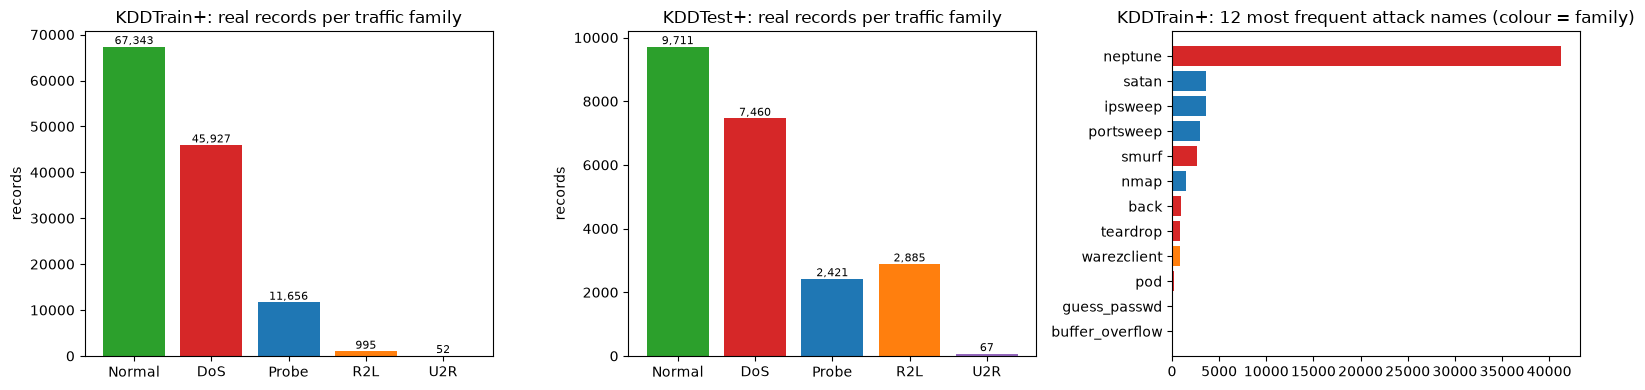

Binary view  KDDTrain+: normal = 67343 | attack = 58630  || KDDTest+: normal = 9711 | attack = 12833


In [6]:
FAM_ORDER  = ["Normal", "DoS", "Probe", "R2L", "U2R"]
FAM_COLOR  = {"Normal": "tab:green", "DoS": "tab:red", "Probe": "tab:blue", "R2L": "tab:orange", "U2R": "tab:purple"}
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, (name, d) in zip(axes[:2], [("KDDTrain+", train_raw), ("KDDTest+", test_raw)]):
    c = d.family.value_counts().reindex(FAM_ORDER)
    ax.bar(c.index, c.values, color=[FAM_COLOR[f] for f in c.index])
    for i, v in enumerate(c.values): ax.text(i, v, f"{v:,}", ha="center", va="bottom", fontsize=8)
    ax.set_title(f"{name}: real records per traffic family"); ax.set_ylabel("records")
top = train_raw[train_raw.y == 1].label.value_counts().head(12)
axes[2].barh(top.index[::-1], top.values[::-1], color=[FAM_COLOR[FAMILY[n]] for n in top.index[::-1]])
axes[2].set_title("KDDTrain+: 12 most frequent attack names (colour = family)")
plt.tight_layout(); plt.show()
print("Binary view  KDDTrain+: normal =", int((train_raw.y == 0).sum()), "| attack =", int((train_raw.y == 1).sum()),
      " || KDDTest+: normal =", int((test_raw.y == 0).sum()), "| attack =", int((test_raw.y == 1).sum()))

### Balanced samples and the preprocessing pipeline

A statevector simulation of 8 qubits needs one circuit run per record and per objective evaluation, so the paper cannot have
used all 125,973 records, and it does not say how many it used. We therefore draw **class-balanced random samples**
(half normal, half attack), which also makes accuracy comparable with the paper's worst rows (chance = 0.5):

* the `KDDTrain+` rows are first split, stratified by label, into a **training pool** (80 %) and a **test pool** (20 %);
* `N_TRAIN` records come from the training pool, `N_TEST` records from the held-out test pool (primary test set, same distribution
  as training), and `N_TEST` more from the official `KDDTest+` file (diagnostic, shifted distribution);
* the two categorical features are ordinal-encoded, byte counts get `log1p`, and everything is scaled to $[0, \pi]$ because the
  `ZZFeatureMap` uses the feature values as rotation angles; the 3-feature variant is `StandardScaler -> PCA(3) -> MinMaxScaler`.

**All transforms are fitted on the training sample only**; test values are clipped to $[0, \pi]$.

In [7]:
BYTES = ["src_bytes", "dst_bytes"]
CATS  = ["protocol_type", "service"]

def balanced_idx(y, n, rs, exclude=()):
    """# CHOICE: n/2 normal + n/2 attack row positions drawn at random (without replacement)."""
    r = np.random.default_rng(rs)
    pick = []
    for cls in (0, 1):
        cand = np.setdiff1d(np.where(y == cls)[0], exclude)
        pick.append(r.choice(cand, n // 2, replace=False))
    return r.permutation(np.concatenate(pick))

class Prep:
    """Fits every transform on the training sample only. transform8 -> angles in [0, pi]; transform3 -> PCA angles in [0, pi]."""
    def fit(self, df):
        self.enc = OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1).fit(df[CATS])
        raw8 = self._raw8(df)
        self.mm8 = MinMaxScaler((0, np.pi)).fit(raw8)
        self.std = StandardScaler().fit(raw8)
        self.pca = PCA(n_components=N_PCA, random_state=SEED).fit(self.std.transform(raw8))
        self.mm3 = MinMaxScaler((0, np.pi)).fit(self.pca.transform(self.std.transform(raw8)))
        return self
    def _raw8(self, df):
        X = df[FEATURES_8].copy()
        X[CATS] = self.enc.transform(df[CATS])
        X[BYTES] = np.log1p(X[BYTES])                 # CHOICE: byte counts are heavy-tailed
        return X[FEATURES_8].values.astype(float)
    def pca_raw(self, df, k=2):                        # raw PCA coordinates (before scaling) for the scatter plots
        return self.pca.transform(self.std.transform(self._raw8(df)))[:, :k]
    def transform8(self, df):
        return np.clip(self.mm8.transform(self._raw8(df)), 0, np.pi)
    def transform3(self, df):
        return np.clip(self.mm3.transform(self.pca.transform(self.std.transform(self._raw8(df)))), 0, np.pi)

def make_data(seed):
    """Everything one seed needs: balanced train / test / KDDTest+ samples and their 8- and 3-feature angle matrices."""
    pool_tr, pool_te = train_test_split(np.arange(len(train_raw)), test_size=TEST_POOL, stratify=train_raw.y, random_state=seed)
    ytr_pool, yte_pool = train_raw.y.values[pool_tr], train_raw.y.values[pool_te]
    d_tr  = train_raw.iloc[pool_tr[balanced_idx(ytr_pool, N_TRAIN, seed)]]
    d_te  = train_raw.iloc[pool_te[balanced_idx(yte_pool, N_TEST, seed + 1)]]
    d_off = test_raw.iloc[balanced_idx(test_raw.y.values, N_TEST, seed + 2)]
    prep = Prep().fit(d_tr)
    out = dict(seed=seed, prep=prep, frames={"train": d_tr, "test": d_te, "kddtest": d_off}, pool_tr=pool_tr, pool_te=pool_te)
    for k, d in out["frames"].items():
        out[k] = dict(X8=prep.transform8(d), X3=prep.transform3(d), y=d.y.values, family=d.family.values)
    return out

DATA = {s: make_data(s) for s in SEEDS}
D0 = DATA[SEEDS[0]]
for k in ("train", "test", "kddtest"):
    print(f"{k:8s} X8 {D0[k]['X8'].shape} X3 {D0[k]['X3'].shape} | normal/attack = {np.bincount(D0[k]['y']).tolist()} | families = {pd.Series(D0[k]['family']).value_counts().to_dict()}")
print("train angles within [0, pi]:", float(D0["train"]["X8"].min()).__round__(3), float(D0["train"]["X8"].max()).__round__(3))
print("PCA explained variance of the 3 components:", D0["prep"].pca.explained_variance_ratio_.round(3))

train    X8 (200, 8) X3 (200, 3) | normal/attack = [100, 100] | families = {'Normal': 100, 'DoS': 81, 'Probe': 18, 'R2L': 1}
test     X8 (200, 8) X3 (200, 3) | normal/attack = [100, 100] | families = {'Normal': 100, 'DoS': 79, 'Probe': 18, 'R2L': 3}
kddtest  X8 (200, 8) X3 (200, 3) | normal/attack = [100, 100] | families = {'Normal': 100, 'DoS': 60, 'Probe': 23, 'R2L': 17}
train angles within [0, pi]: 0.0 3.142
PCA explained variance of the 3 components: [0.427 0.18  0.153]


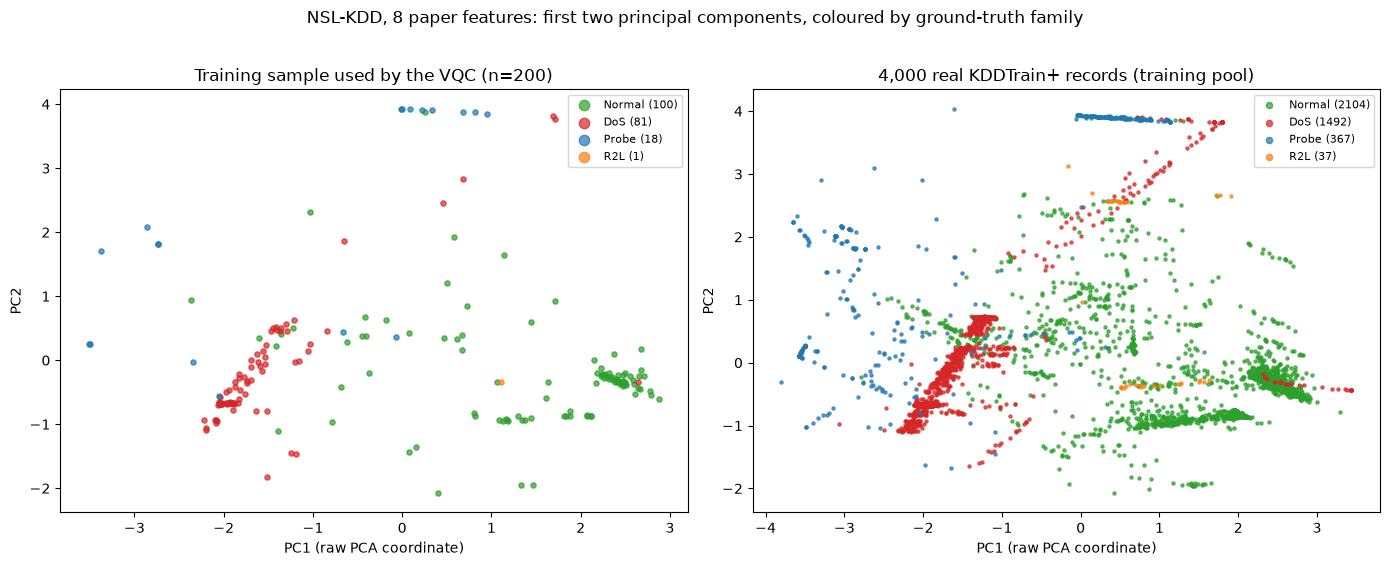

In [8]:
# Scatter 1: raw PCA coordinates (fitted on the training sample). Every point is a real record, coloured by its true family.
# Left: the model's own training sample. Right: a larger display sample of real KDDTrain+ records from the training pool
# (projected with the training-fitted pipeline) to show the structure behind the 120-200 training points.
prep0 = D0["prep"]
r = np.random.default_rng(SEED)
disp_idx = r.choice(D0["pool_tr"], 4000, replace=False)
disp = train_raw.iloc[disp_idx]
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
for ax, (title, d) in zip(axes, [(f"Training sample used by the VQC (n={len(D0['frames']['train'])})", D0["frames"]["train"]),
                                  ("4,000 real KDDTrain+ records (training pool)", disp)]):
    P = prep0.pca_raw(d, 2)
    for fam in FAM_ORDER:
        m = (d.family.values == fam)
        if not m.any(): continue
        ax.scatter(P[m, 0], P[m, 1], s=14 if len(d) < 1000 else 5, alpha=0.7, c=FAM_COLOR[fam], label=f"{fam} ({m.sum()})")
    ax.set_xlabel("PC1 (raw PCA coordinate)"); ax.set_ylabel("PC2"); ax.set_title(title); ax.legend(markerscale=2, fontsize=8)
plt.suptitle("NSL-KDD, 8 paper features: first two principal components, coloured by ground-truth family", y=1.02)
plt.tight_layout(); plt.show()

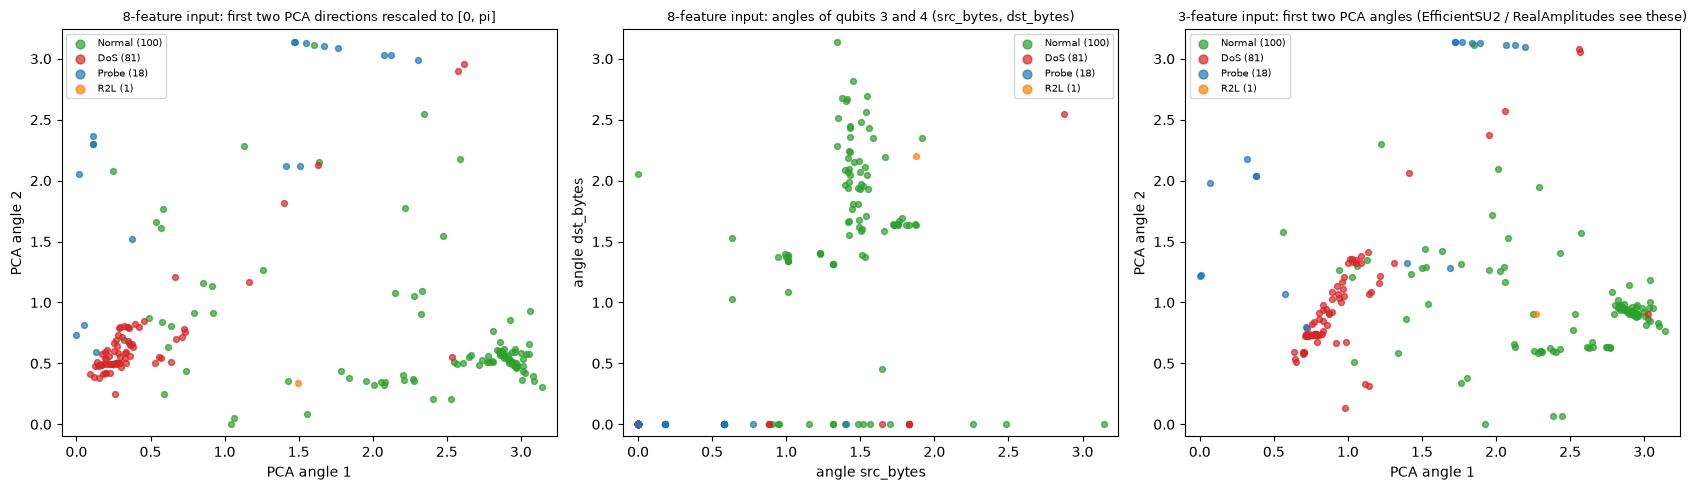

In [9]:
# Scatter 2: the angles the circuit actually receives (all in [0, pi]), ground-truth family colours, training sample.
fig, axes = plt.subplots(1, 3, figsize=(17, 5))
tr = D0["train"]
for ax, (title, A, lab) in zip(axes, [("8-feature input: first two PCA directions rescaled to [0, pi]", None, ("PCA angle 1", "PCA angle 2")),
                                      ("8-feature input: angles of qubits 3 and 4 (src_bytes, dst_bytes)", tr["X8"][:, [2, 3]], ("angle src_bytes", "angle dst_bytes")),
                                      ("3-feature input: first two PCA angles (EfficientSU2 / RealAmplitudes see these)", tr["X3"][:, :2], ("PCA angle 1", "PCA angle 2"))]):
    if A is None:                                         # PCA of the 8 raw angles, rescaled to [0, pi] for display
        Z = PCA(2, random_state=SEED).fit(tr["X8"]).transform(tr["X8"])
        A = MinMaxScaler((0, np.pi)).fit_transform(Z)
    for fam in FAM_ORDER:
        m = tr["family"] == fam
        if not m.any(): continue
        ax.scatter(A[m, 0], A[m, 1], s=18, alpha=0.7, c=FAM_COLOR[fam], label=f"{fam} ({m.sum()})")
    ax.set_xlim(-0.1, np.pi + 0.1); ax.set_ylim(-0.1, np.pi + 0.1)
    ax.set_title(title, fontsize=9); ax.set_xlabel(lab[0]); ax.set_ylabel(lab[1]); ax.legend(fontsize=7, markerscale=1.5)
plt.tight_layout(); plt.show()

## 2. Classical baselines on identical inputs

The paper does not compare its VQC with any classical classifier on NSL-KDD. Before training anything quantum we ask what plain
classical models reach on **exactly the angles the circuit receives**: the same training sample and the same test samples, with 8
features or with the 3 PCA angles. Three models (random forest, RBF-SVC, logistic regression) are used, plus a random forest on all
41 features of the same training rows as a reference for how much information the 8-feature selection throws away. Everything is
repeated over the seeds.

In [10]:
def attack_metrics(y, pred):
    """Attack = positive class (the security-critical class)."""
    return dict(acc=accuracy_score(y, pred), precision=precision_score(y, pred, zero_division=0),
                recall=recall_score(y, pred, zero_division=0), f1=f1_score(y, pred, zero_division=0))

def baseline_models(seed):
    return {"RandomForest": RandomForestClassifier(n_estimators=200, random_state=seed),
            "SVC (rbf)": SVC(kernel="rbf", C=1.0, random_state=seed),
            "LogisticRegression": LogisticRegression(max_iter=2000, random_state=seed)}

rows = []
for s, D in DATA.items():
    for feat in ("X8", "X3"):
        for name, model in baseline_models(s).items():
            t0 = time.perf_counter(); model.fit(D["train"][feat], D["train"]["y"]); t_fit = time.perf_counter() - t0
            for split in ("train", "test", "kddtest"):
                rows.append(dict(seed=s, inputs="8 features" if feat == "X8" else "3 PCA features", model=name, split=split,
                                 seconds=t_fit, **attack_metrics(D[split]["y"], model.predict(D[split][feat]))))
    # reference: random forest on ALL 41 features (one-hot of the 3 categoricals), same training rows
    allc = [c for c in NSL_COLS if c not in ("label", "difficulty")]
    cats3 = ["protocol_type", "service", "flag"]
    parts = {k: D["frames"][k][allc].reset_index(drop=True) for k in ("train", "test", "kddtest")}
    big = pd.get_dummies(pd.concat(parts.values(), keys=parts.keys()), columns=cats3).astype(float)
    rf = RandomForestClassifier(n_estimators=200, random_state=s).fit(big.loc["train"], D["train"]["y"])
    for split in ("train", "test", "kddtest"):
        rows.append(dict(seed=s, inputs="all 41 features", model="RandomForest", split=split, seconds=np.nan,
                         **attack_metrics(D[split]["y"], rf.predict(big.loc[split]))))
BASE = pd.DataFrame(rows)
summary = (BASE.groupby(["inputs", "model", "split"])[["acc"]].agg(["mean", "std"]).round(3).unstack("split"))
print("Classical baselines: accuracy (mean, std over seeds) on the training sample, the held-out test pool and KDDTest+:")
display(summary)

Classical baselines: accuracy (mean, std over seeds) on the training sample, the held-out test pool and KDDTest+:


acc                                    
                                      mean                   std              
split                              kddtest   test  train kddtest   test  train
inputs          model                                                         
3 PCA features  LogisticRegression   0.772  0.923  0.873   0.053  0.025  0.026
                RandomForest         0.813  0.955  1.000   0.020  0.015  0.000
                SVC (rbf)            0.798  0.945  0.945   0.038  0.015  0.023
8 features      LogisticRegression   0.782  0.927  0.895   0.035  0.024  0.052
                RandomForest         0.823  0.970  1.000   0.038  0.000  0.000
                SVC (rbf)            0.813  0.952  0.960   0.038  0.016  0.035
all 41 features RandomForest         0.825  0.975  1.000   0.040  0.005  0.000

## Quantum Circuit Architecture

The VQC is built from three pieces (paper Fig. 1-2): a **feature map** that writes the record into a quantum state, a **variational
ansatz** whose rotation angles are trained, and a **measurement** of all qubits whose bit-strings are mapped to the two classes.

* **Feature map:** `zz_feature_map(n, reps=2, entanglement="full")`: Hadamards, one phase rotation per feature, and a
  CNOT-phase-CNOT block for every qubit pair (second-order $\varphi(x_i,x_j)=(\pi-x_i)(\pi-x_j)$ terms).
* **Ansatz:** `real_amplitudes(n, reps=3)` ($R_Y$ rotations only) or `efficient_su2(n, reps=3)` ($R_Y$ and $R_Z$), each followed by
  CNOT entanglement layers; the paper does not give the number of repetitions or the entanglement pattern, so Qiskit's defaults
  are used (`reps=3`, `"reverse_linear"` entanglement; documented as a choice in the table above).
* **Read-out:** all qubits are measured; Qiskit's `VQC` interprets the bit-string by its parity (class 0 = even, class 1 = odd).

The cell below builds the four architectures the paper compares (8 or 3 qubits x two ansaetze) exactly as the training code does and
draws the circuit stored inside `vqc.neural_network`, i.e. **the circuit object that is sent to the sampler** (the `VQC` appends the
measurements itself). Printed: qubits, depth after decomposition into basic gates, trainable parameters and input parameters.

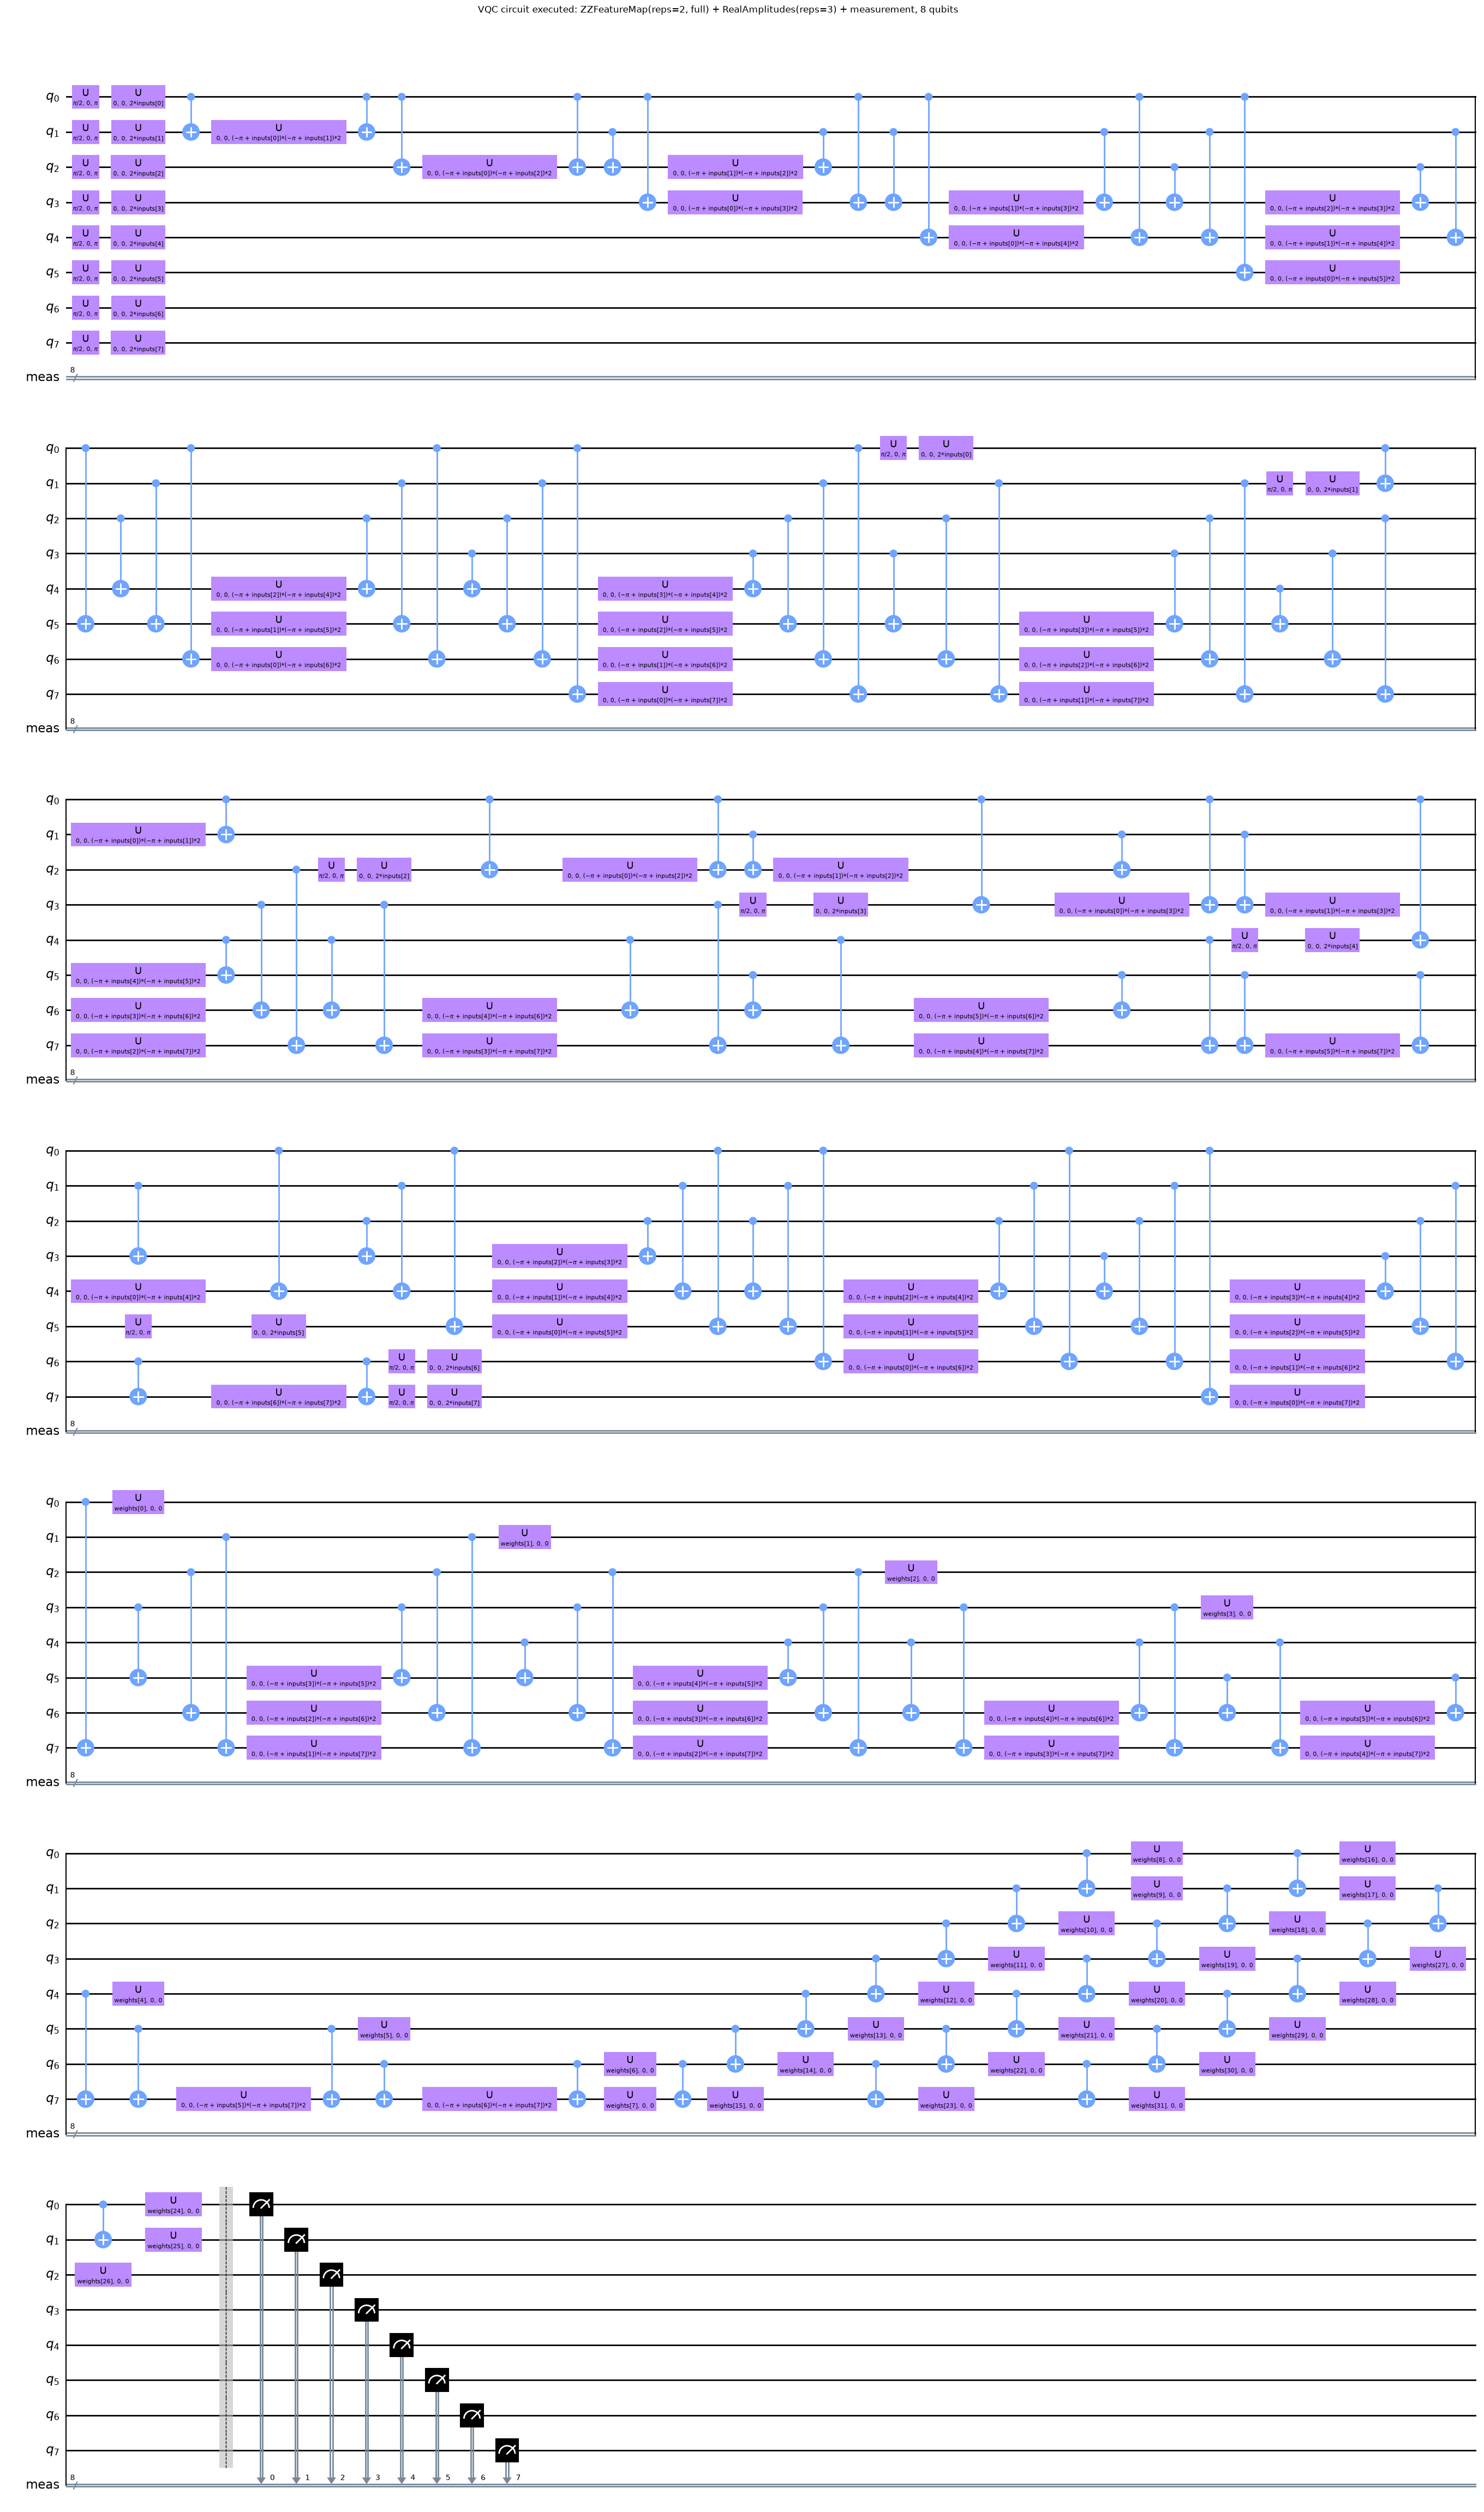

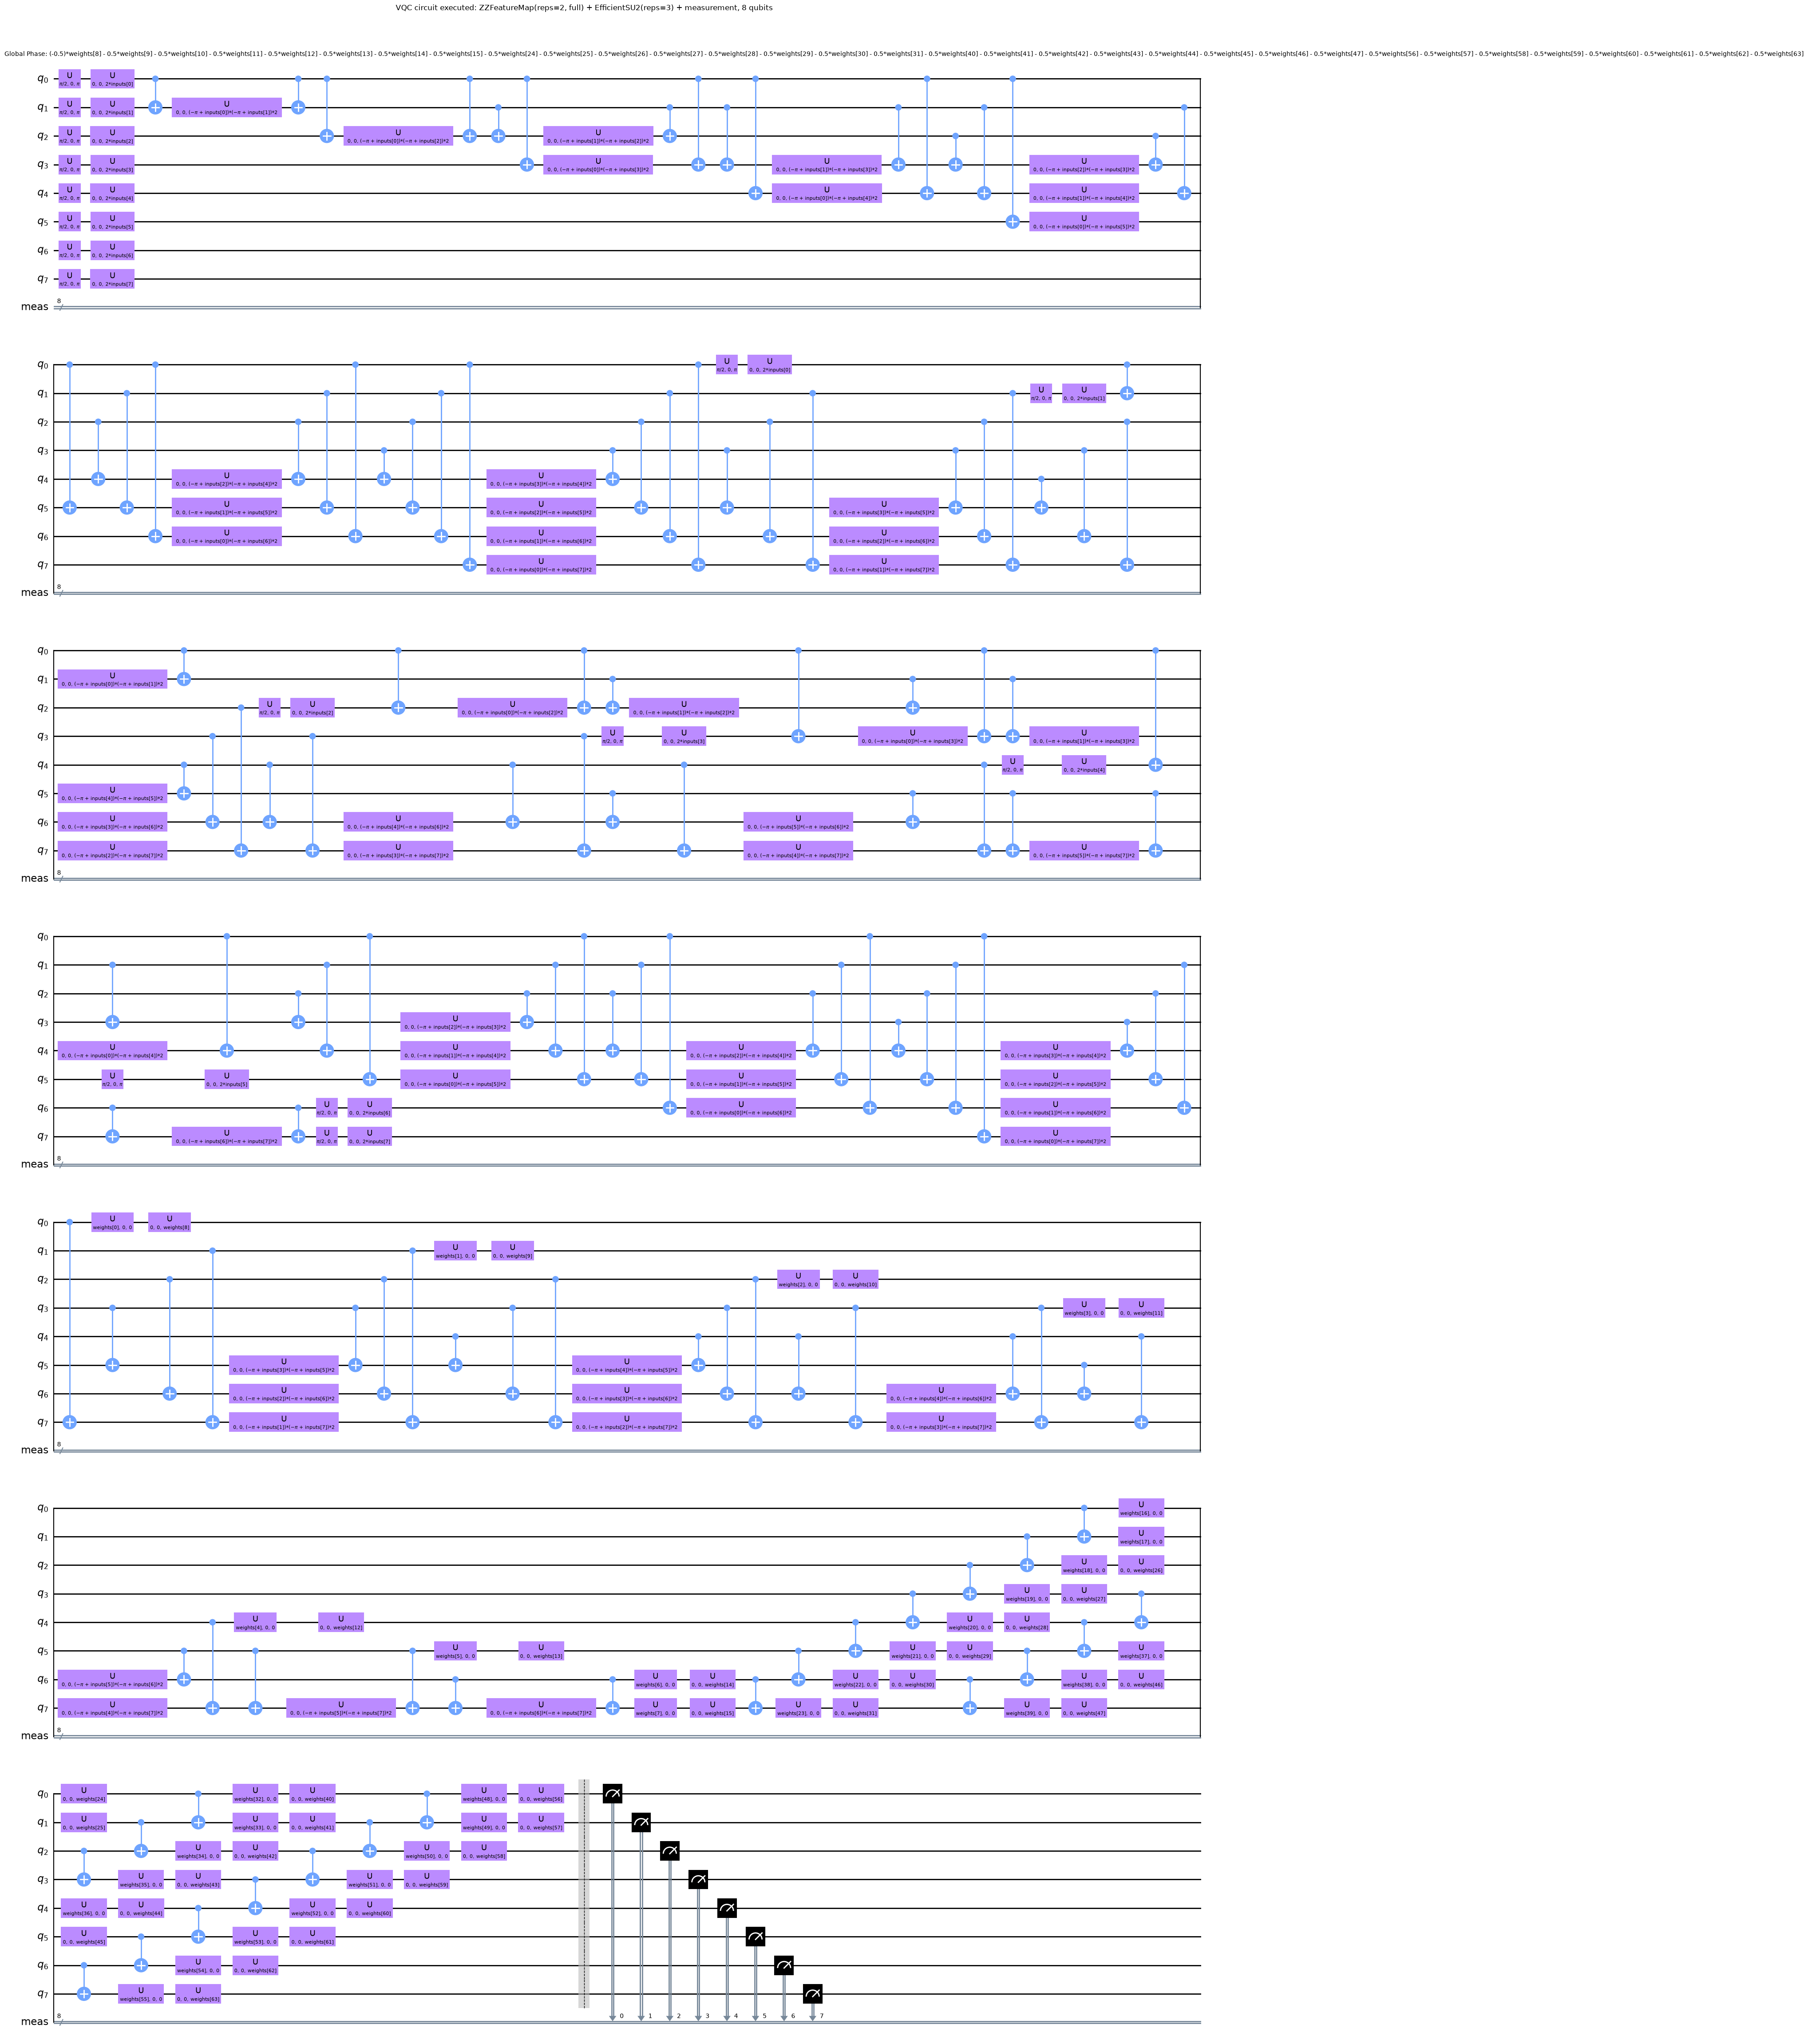

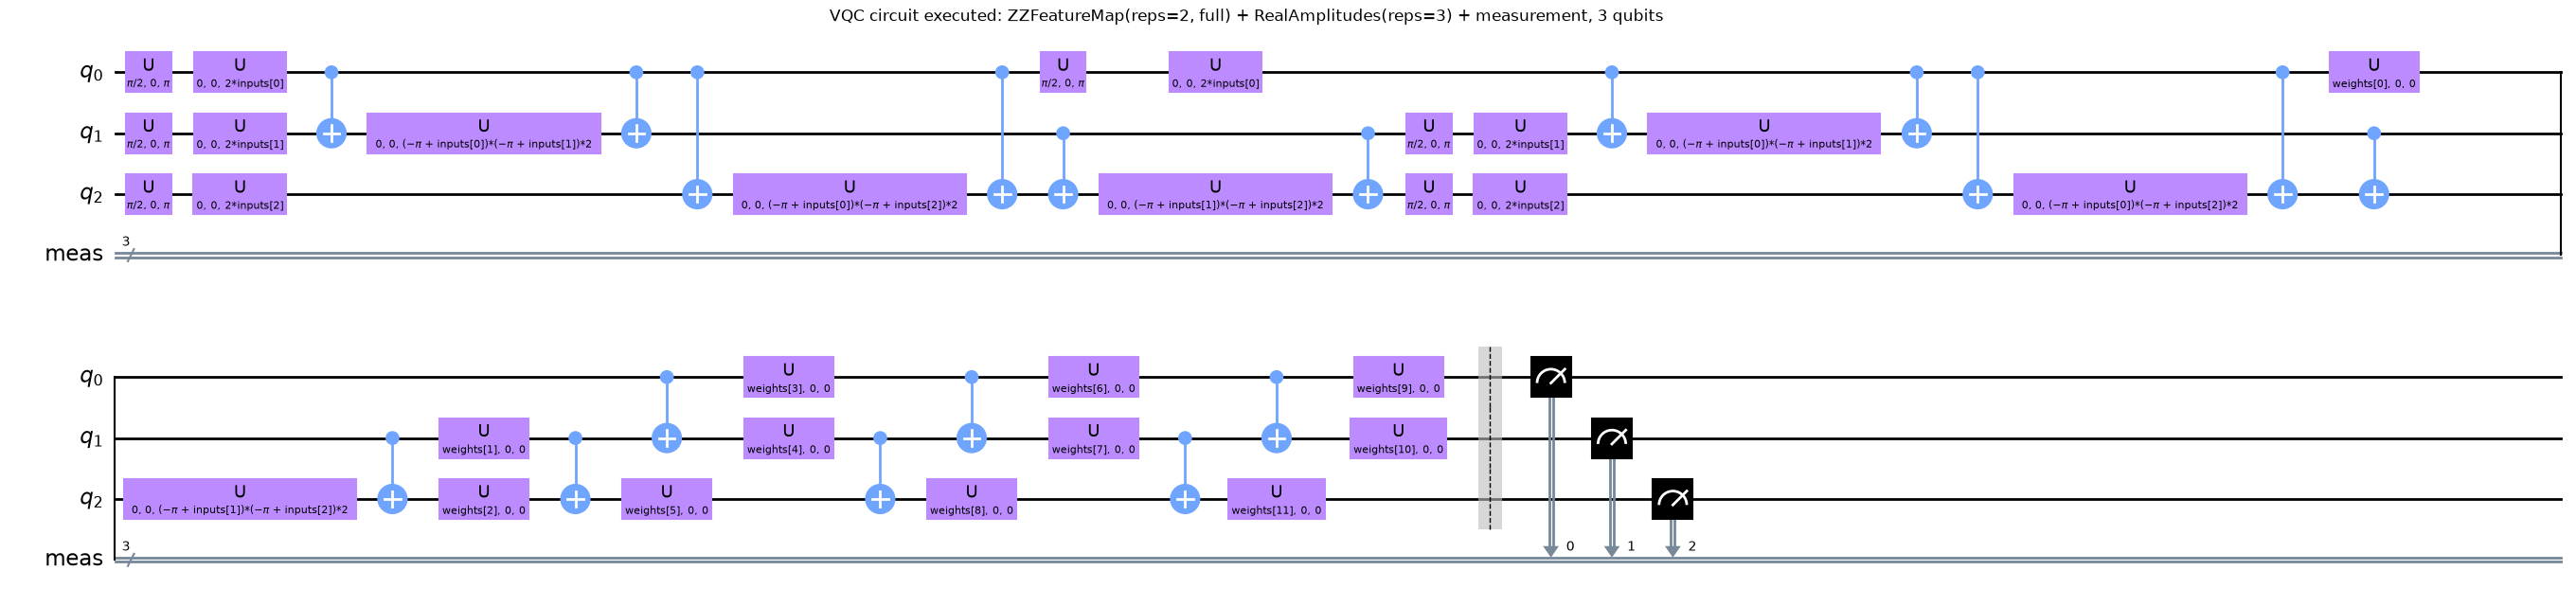

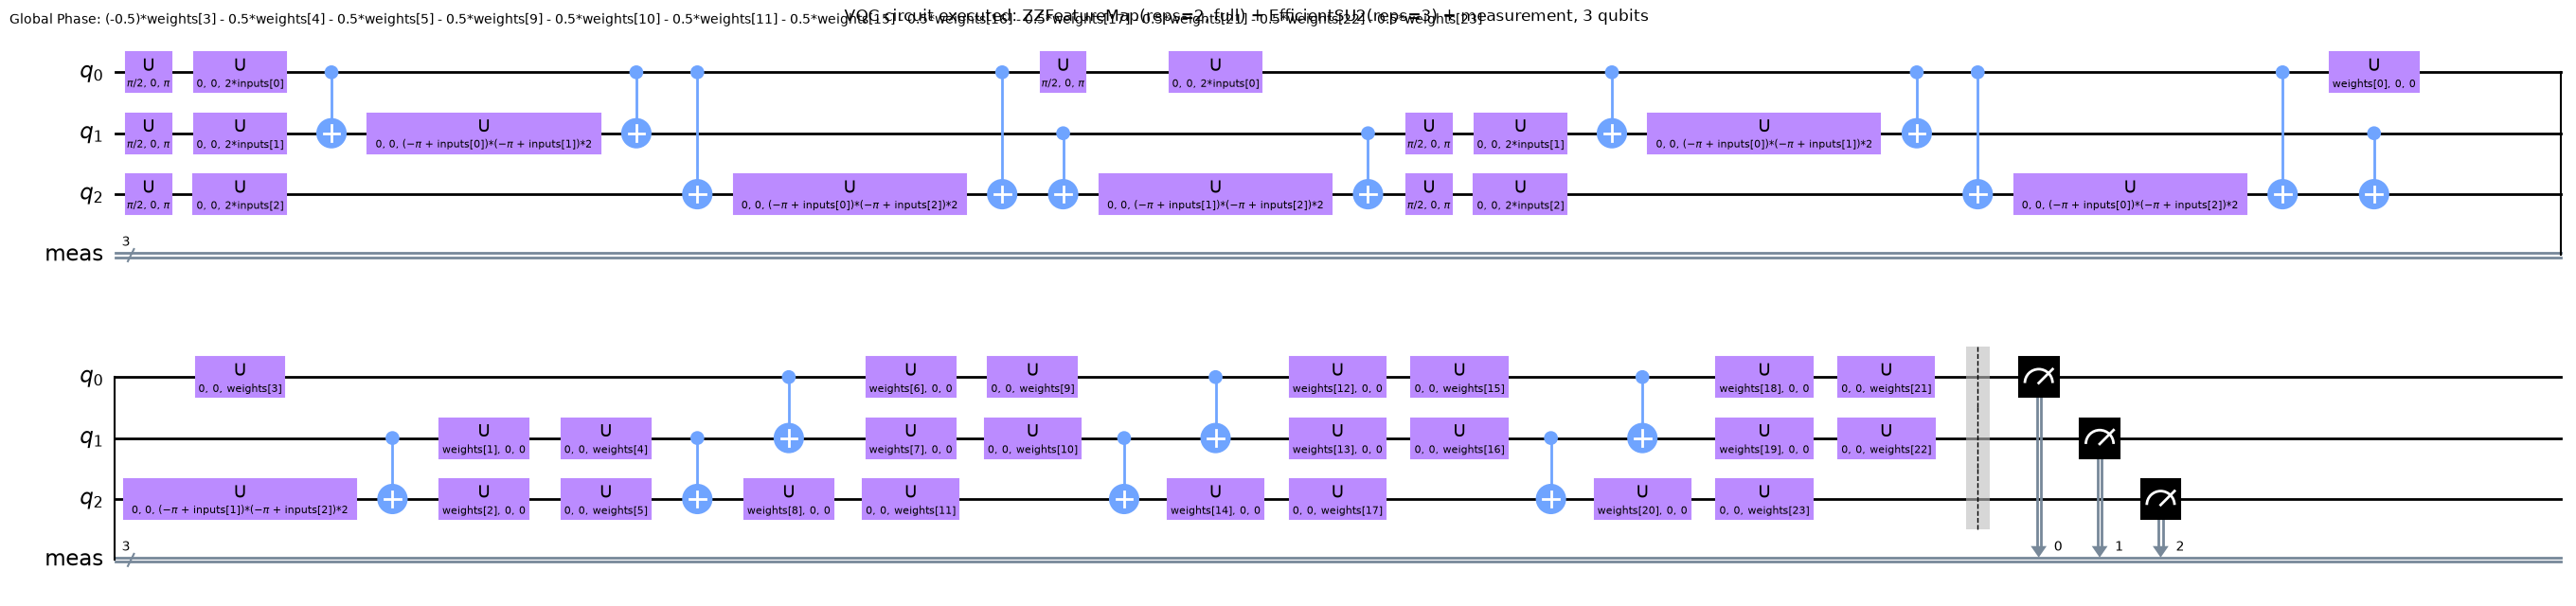

,qubits,depth_decomposed,trainable_params,input_params,two_qubit_gates
architecture,,,,,
"RealAmplitudes, 8 qubits",8,83,32,8,133
"EfficientSU2, 8 qubits",8,87,64,8,133
"RealAmplitudes, 3 qubits",3,33,12,3,18
"EfficientSU2, 3 qubits",3,37,24,3,18


Assumptions where the paper is silent: ansatz repetitions (3), entanglement of the ansatz (Qiskit default reverse_linear), ZZFeatureMap repetitions (2, full entanglement), read-out (parity), shots (1024), initial parameters (seeded random).


In [11]:
ANSATZE = {"RealAmplitudes": real_amplitudes, "EfficientSU2": efficient_su2}

def build_vqc(ansatz_name, n_qubits, optimizer=None, callback=None, seed=SEED):
    """The single place where a VQC is constructed: used for the drawings below and for all training runs."""
    fm  = zz_feature_map(n_qubits, reps=FM_REPS, entanglement="full")
    ans = ANSATZE[ansatz_name](n_qubits, reps=ANSATZ_REPS)
    return VQC(feature_map=fm, ansatz=ans, optimizer=optimizer, sampler=make_sampler(seed), callback=callback)

arch_rows = []
for nq in (8, 3):
    for aname in ANSATZE:
        v = build_vqc(aname, nq)
        qnn = v.neural_network
        # The QNN stores the circuit it sends to the sampler in `_circuit` (re-parameterised, measure_all appended);
        # `qnn.circuit` is the same circuit without the measurements. Fall back to adding them if the private attribute is absent.
        circ = getattr(qnn, "_circuit", None) or qnn.circuit.measure_all(inplace=False)
        assert circ.count_ops().get("measure", 0) == nq
        dec = circ.decompose(reps=3)
        assert qnn.num_inputs == nq and circ.num_qubits == nq and circ.num_clbits == nq
        arch_rows.append(dict(architecture=f"{aname}, {nq} qubits", qubits=circ.num_qubits, depth_decomposed=dec.depth(),
                              trainable_params=qnn.num_weights, input_params=qnn.num_inputs,
                              two_qubit_gates=sum(n for g, n in dec.count_ops().items() if g in ("cx", "cz"))))
        fig = dec.draw("mpl", fold=40, style="clifford")
        fig.suptitle(f"VQC circuit executed: ZZFeatureMap(reps={FM_REPS}, full) + {aname}(reps={ANSATZ_REPS}) + measurement, {nq} qubits", y=0.9)
        display(fig); plt.close(fig)
display(pd.DataFrame(arch_rows).set_index("architecture"))
print("Assumptions where the paper is silent: ansatz repetitions (3), entanglement of the ansatz (Qiskit default reverse_linear), "
      "ZZFeatureMap repetitions (2, full entanglement), read-out (parity), shots (1024), initial parameters (seeded random).")

## 3. Training the VQC in the six configurations of Table I

For every configuration and seed a `VQC` is trained on the balanced training sample. The objective is the cross-entropy between the
measured class probabilities and the one-hot labels (the "cost function" of the paper's Fig. 2-3). A callback stores the objective
value at every evaluation and redraws the curve every few evaluations; this is the paper's Fig. 4 (8 features) and Fig. 5 (3 features).

* **COBYLA** (derivative free) gets `COBYLA_MAXITER` iterations (paper: 100 training epochs). Each iteration is one objective
  evaluation = one pass of all training circuits through the simulator. COBYLA first spends one evaluation per parameter to
  build its initial simplex, so with 33 or 65 parameters (8 qubits) the first 33-65 evaluations are exploration.
* **AQGD** (our reading of "AQSD") needs the parameter-shift gradient: 2 x (number of weights) circuit evaluations per sample per
  epoch. For 32 or 64 weights this is hundreds of times more work than one COBYLA step, which is why the paper's AQSD runs took
  7x longer than its COBYLA runs. We give AQGD a smaller budget (`AQGD_N_TRAIN` samples, `AQGD_MAXITER` epochs); the comparison with the
  paper is therefore *qualitative* for these two rows. The scores after training are still computed on the full training sample.

Training time is the wall-clock time of `fit` on this machine (the paper's times are Colab times, so only ratios are comparable).

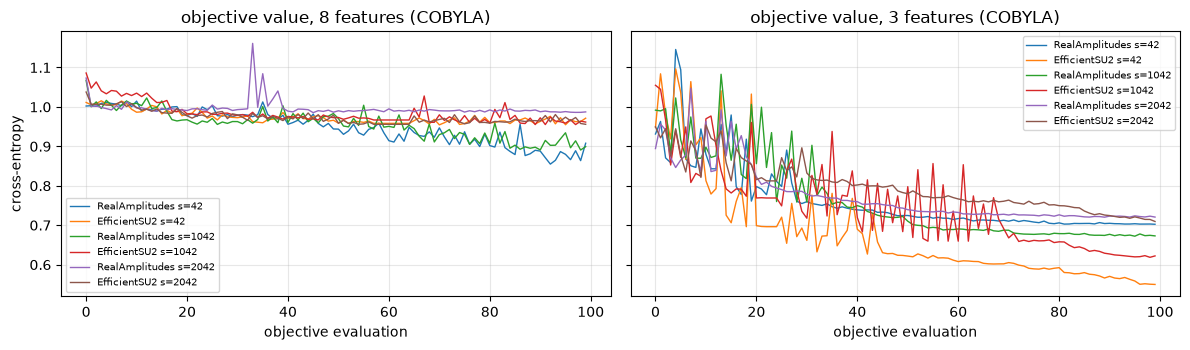

RealAmplitudes  8 features AQSD    seed 42: evals=   4 fit=  323.8s | train acc 0.525 | test acc 0.485 | KDDTest+ acc 0.560 | final loss 1.029
EfficientSU2    8 features AQSD    seed 42: evals=   4 fit= 1366.7s | train acc 0.550 | test acc 0.515 | KDDTest+ acc 0.575 | final loss 1.023
RealAmplitudes  8 features COBYLA  seed 42: evals= 100 fit=  466.1s | train acc 0.800 | test acc 0.755 | KDDTest+ acc 0.705 | final loss 0.908
EfficientSU2    8 features COBYLA  seed 42: evals= 100 fit=  721.9s | train acc 0.640 | test acc 0.635 | KDDTest+ acc 0.625 | final loss 0.971
RealAmplitudes  3 features COBYLA  seed 42: evals= 100 fit=  333.0s | train acc 0.785 | test acc 0.775 | KDDTest+ acc 0.735 | final loss 0.702
EfficientSU2    3 features COBYLA  seed 42: evals= 100 fit=  253.9s | train acc 0.835 | test acc 0.850 | KDDTest+ acc 0.780 | final loss 0.550
RealAmplitudes  8 features COBYLA  seed 1042: evals= 100 fit=  475.7s | train acc 0.695 | test acc 0.635 | KDDTest+ acc 0.530 | final loss 0.8

In [12]:
CONFIGS = [  # (ansatz, n_qubits, optimizer) = the six rows of the paper's Table I
    ("RealAmplitudes", 8, "AQSD"), ("EfficientSU2", 8, "AQSD"),
    ("RealAmplitudes", 8, "COBYLA"), ("EfficientSU2", 8, "COBYLA"),
    ("RealAmplitudes", 3, "COBYLA"), ("EfficientSU2", 3, "COBYLA")]
if not RUN_AQGD:
    CONFIGS = [c for c in CONFIGS if c[2] != "AQSD"]

class RecordingAQGD(AQGD):
    """AQGD that reports the objective value at every epoch. (This qiskit-machine-learning version only forwards the VQC
    callback for SciPy optimisers, so the objective values of a non-SciPy optimiser have to be recorded by wrapping `fun`.)"""
    def __init__(self, record, **kwargs):
        super().__init__(**kwargs); self._record = record
    def minimize(self, fun, x0, jac=None, bounds=None):
        def recorded(w):
            v = fun(w); self._record(w, v); return v
        return super().minimize(recorded, x0, jac, bounds)

RUNS, CURVES, RUN_LOG = [], {}, []            # RUNS: one dict per (config, seed); CURVES[(config, seed)] = objective values

def live_plot():
    clear_output(wait=True)
    fig, axes = plt.subplots(1, 2, figsize=(12, 3.6), sharey=True)
    for ax, nq in zip(axes, (8, 3)):
        for (cfg, s), cur in CURVES.items():
            if cfg[1] == nq and cfg[2] == "COBYLA" and len(cur):
                ax.plot(cur, label=f"{cfg[0]} s={s}", lw=1)
        ax.set_title(f"objective value, {nq} features (COBYLA)"); ax.set_xlabel("objective evaluation"); ax.grid(alpha=0.3); ax.legend(fontsize=7)
    axes[0].set_ylabel("cross-entropy"); plt.tight_layout(); plt.show()

def run_one(cfg, seed):
    aname, nq, optname = cfg
    D = DATA[seed]; feat = "X8" if nq == 8 else "X3"
    Xtr, ytr = D["train"][feat], D["train"]["y"]
    if optname == "AQSD":                                    # stratified subset for the expensive gradient optimiser
        sub = balanced_idx(ytr, AQGD_N_TRAIN, seed + 7)
        Xfit, yfit, opt = Xtr[sub], ytr[sub], RecordingAQGD(lambda w, v: callback(w, v), maxiter=AQGD_MAXITER)
    else:
        Xfit, yfit, opt = Xtr, ytr, COBYLA(maxiter=COBYLA_MAXITER)
    algorithm_globals.random_seed = seed
    CURVES[(cfg, seed)] = []
    def callback(weights, loss, key=(cfg, seed)):
        CURVES[key].append(float(loss))
        if optname == "COBYLA" and len(CURVES[key]) % LIVE_PLOT_EVERY == 0: live_plot()
    vqc = build_vqc(aname, nq, optimizer=opt, callback=callback, seed=seed)
    t0 = time.perf_counter(); vqc.fit(Xfit, yfit); t_fit = time.perf_counter() - t0
    rec = dict(ansatz=aname, features=nq, optimizer=optname, seed=seed, fit_seconds=t_fit, evaluations=len(CURVES[(cfg, seed)]),
               n_fit=len(yfit), n_params=vqc.neural_network.num_weights, final_loss=CURVES[(cfg, seed)][-1], model=vqc)
    for split in ("train", "test", "kddtest"):
        pred = vqc.predict(DATA[seed][split][feat])
        rec[split] = attack_metrics(DATA[seed][split]["y"], np.asarray(pred).ravel()); rec[split + "_pred"] = np.asarray(pred).ravel()
    return rec

t_all = time.perf_counter()
for seed_i, seed in enumerate(SEEDS):
    for cfg in CONFIGS:
        if cfg[2] == "AQSD" and seed_i >= AQGD_ON_SEEDS: continue
        rec = run_one(cfg, seed); RUNS.append(rec)
        RUN_LOG.append(f"{cfg[0]:15s} {cfg[1]} features {cfg[2]:7s} seed {seed}: evals={rec['evaluations']:4d} fit={rec['fit_seconds']:7.1f}s "
              f"| train acc {rec['train']['acc']:.3f} | test acc {rec['test']['acc']:.3f} | KDDTest+ acc {rec['kddtest']['acc']:.3f} | final loss {rec['final_loss']:.3f}")
live_plot()
print("\n".join(RUN_LOG))
TOTAL_TRAIN_MIN = (time.perf_counter() - t_all) / 60
print(f"\nTotal training time of all VQC runs: {TOTAL_TRAIN_MIN:.1f} min")

## 4. Metrics: Table I of this notebook, loss curves and confusion matrices

Table I of the paper lists test score, train score and training time for the six configurations. "Score" is accuracy. Below, the
same table is recomputed (mean and standard deviation over the seeds; the held-out test pool is the primary test set, `KDDTest+` is
shown as a diagnostic), followed by the paper's Fig. 4 and 5 (objective value versus iteration, 8 and 3 features) and confusion
matrices with **attack as the positive class** (top-left cell = attacks caught).

This notebook's Table I (mean over seeds; 'Test' = held-out balanced test pool):


,QCircuit,Features,Optimizer,Test,Test std,Train,Test F1 (attack),Test recall (attack),KDDTest+ acc,Train time (s),evaluations,runs
0,RealAmplitudes,8,AQSD,0.485,0.000,0.525,0.352,0.280,0.560,324,4,1
1,EfficientSU2,8,AQSD,0.515,0.000,0.550,0.349,0.260,0.575,1367,4,1
2,RealAmplitudes,8,COBYLA,0.657,0.073,0.702,0.663,0.667,0.573,513,100,3
3,EfficientSU2,8,COBYLA,0.677,0.049,0.673,0.681,0.693,0.613,549,100,3
4,RealAmplitudes,3,COBYLA,0.780,0.023,0.788,0.785,0.807,0.715,309,100,3
5,EfficientSU2,3,COBYLA,0.850,0.041,0.817,0.853,0.863,0.737,352,100,3


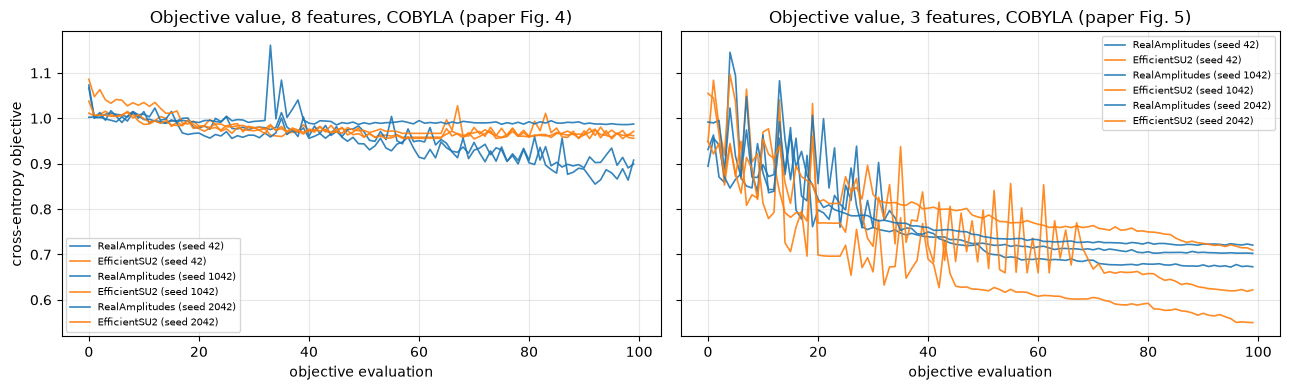

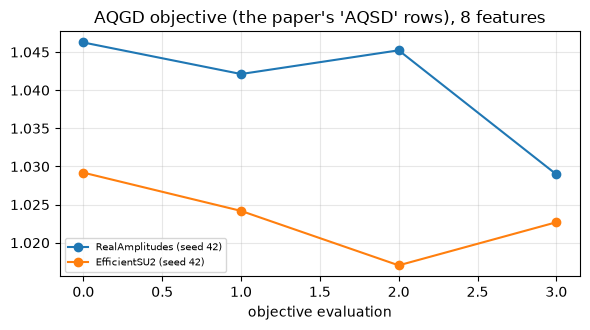

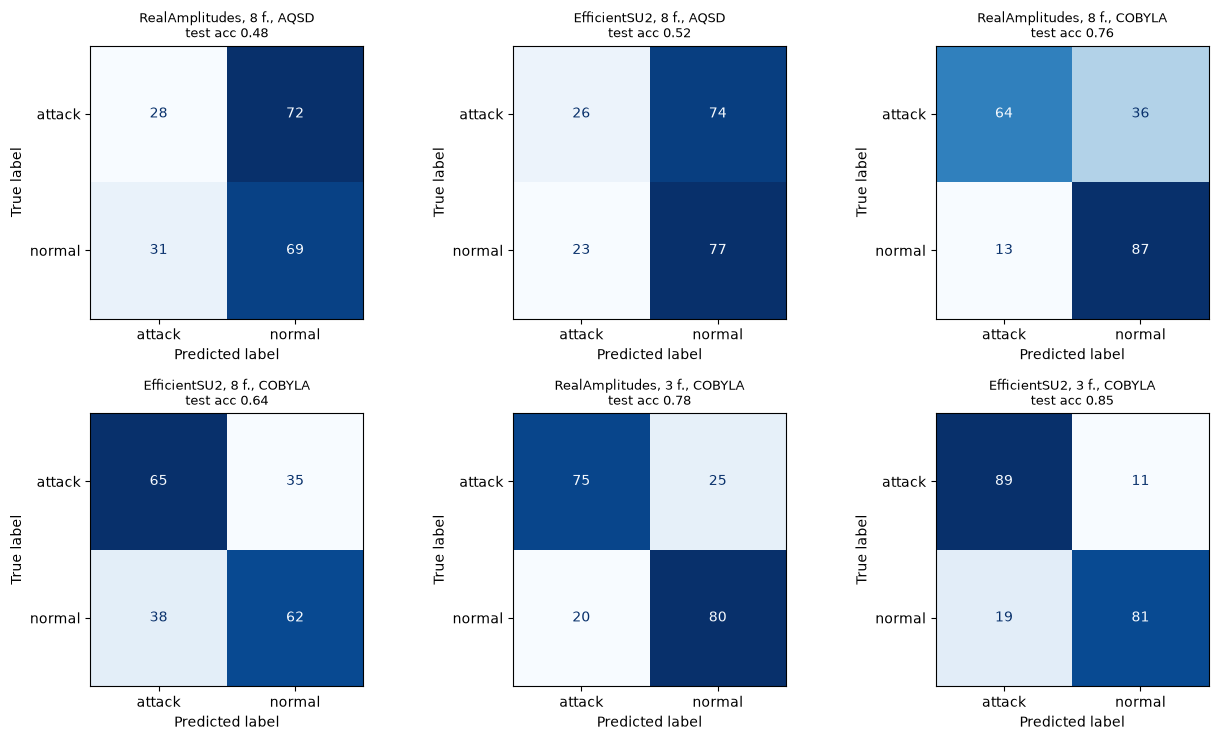

Classical baselines on the same test pool (accuracy):


acc
inputs          model                    
3 PCA features  LogisticRegression  0.923
                RandomForest        0.955
                SVC (rbf)           0.945
8 features      LogisticRegression  0.927
                RandomForest        0.970
                SVC (rbf)           0.952
all 41 features RandomForest        0.975

In [13]:
def agg(cfg, field, split=None):
    vals = [r[split][field] if split else r[field] for r in RUNS if (r["ansatz"], r["features"], r["optimizer"]) == cfg]
    return np.mean(vals) if vals else np.nan, (np.std(vals) if len(vals) > 1 else 0.0), len(vals)

rows = []
for cfg in CONFIGS:
    te, te_s, n = agg(cfg, "acc", "test"); tr_, tr_s, _ = agg(cfg, "acc", "train"); kd, kd_s, _ = agg(cfg, "acc", "kddtest")
    f1, _, _ = agg(cfg, "f1", "test"); rec_, _, _ = agg(cfg, "recall", "test"); tt, _, _ = agg(cfg, "fit_seconds")
    ev, _, _ = agg(cfg, "evaluations")
    rows.append({"QCircuit": cfg[0], "Features": cfg[1], "Optimizer": cfg[2], "Test": round(te, 3), "Test std": round(te_s, 3),
                 "Train": round(tr_, 3), "Test F1 (attack)": round(f1, 3), "Test recall (attack)": round(rec_, 3),
                 "KDDTest+ acc": round(kd, 3), "Train time (s)": round(tt), "evaluations": round(ev), "runs": n})
TABLE1 = pd.DataFrame(rows)
print("This notebook's Table I (mean over seeds; 'Test' = held-out balanced test pool):")
display(TABLE1)

fig, axes = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
for ax, nq in zip(axes, (8, 3)):
    for (cfg, s), cur in CURVES.items():
        if cfg[1] == nq and cfg[2] == "COBYLA":
            ax.plot(cur, lw=1.2, label=f"{cfg[0]} (seed {s})", color="tab:blue" if cfg[0] == "RealAmplitudes" else "tab:orange", alpha=0.9)
    ax.set_title(f"Objective value, {nq} features, COBYLA (paper Fig. {4 if nq == 8 else 5})"); ax.set_xlabel("objective evaluation"); ax.grid(alpha=0.3); ax.legend(fontsize=7)
axes[0].set_ylabel("cross-entropy objective"); plt.tight_layout(); plt.show()

# AQGD curves (one value per epoch)
aq = {k: v for k, v in CURVES.items() if k[0][2] == "AQSD"}
if aq:
    fig, ax = plt.subplots(figsize=(6, 3.4))
    for (cfg, s), cur in aq.items(): ax.plot(cur, marker="o", label=f"{cfg[0]} (seed {s})")
    ax.set_title("AQGD objective (the paper's 'AQSD' rows), 8 features"); ax.set_xlabel("objective evaluation"); ax.legend(fontsize=7); ax.grid(alpha=0.3)
    plt.tight_layout(); plt.show()

first = {cfg: next(r for r in RUNS if (r["ansatz"], r["features"], r["optimizer"]) == cfg) for cfg in CONFIGS if any((r["ansatz"], r["features"], r["optimizer"]) == cfg for r in RUNS)}
fig, axes = plt.subplots(2, 3, figsize=(13, 7.5))
for ax, (cfg, r) in zip(axes.ravel(), first.items()):
    y = DATA[r["seed"]]["test"]["y"]
    cm = confusion_matrix(y, r["test_pred"], labels=[1, 0])
    ConfusionMatrixDisplay(cm, display_labels=["attack", "normal"]).plot(ax=ax, colorbar=False, cmap="Blues")
    ax.set_title(f"{cfg[0]}, {cfg[1]} f., {cfg[2]}\ntest acc {r['test']['acc']:.2f}", fontsize=9)
plt.tight_layout(); plt.show()

# baselines next to the VQC rows (8 / 3 features), mean over seeds, held-out test pool
bt = BASE[BASE.split == "test"].groupby(["inputs", "model"]).acc.mean().round(3)
print("Classical baselines on the same test pool (accuracy):"); display(bt.to_frame("acc"))

## 5. Paper versus this notebook

Each row below is one number or qualitative statement the paper makes. A numeric claim is **reproduced** when our mean lies within
0.02 (two accuracy points) of the paper's value, **not reached** when it is lower by more, and **exceeded** when it is higher by
more. With a test set of `N_TEST` records one standard error of an accuracy near 0.85 is $\sqrt{0.85\cdot0.15/N_{test}}$
(0.036 for 100 records, 0.025 for 200), so differences below that cannot be told apart; the second column of the output shows
the standard deviation over seeds as a hint. Training times are on different hardware and can only be compared as ratios.

In [14]:
PAPER_T1 = {  # (ansatz, features, optimizer): (test, train, seconds)   -- Table I of the paper
    ("RealAmplitudes", 8, "AQSD"): (0.49, 0.45, 9047), ("EfficientSU2", 8, "AQSD"): (0.46, 0.42, 9738),
    ("RealAmplitudes", 8, "COBYLA"): (0.89, 0.87, 1316), ("EfficientSU2", 8, "COBYLA"): (0.79, 0.81, 1441),
    ("RealAmplitudes", 3, "COBYLA"): (0.81, 0.82, 275), ("EfficientSU2", 3, "COBYLA"): (0.90, 0.93, 356)}
TOL = 0.02

def verdict(paper, ours, tol=TOL):
    if ours is None or np.isnan(ours): return "not run here"
    if abs(ours - paper) <= tol: return "reproduced"
    return "exceeded" if ours > paper else "not reached"

rows = []
for cfg in CONFIGS:
    p_te, p_tr, p_s = PAPER_T1[cfg]
    te, te_s, n = agg(cfg, "acc", "test"); tr_, _, _ = agg(cfg, "acc", "train")
    note = "gradient optimiser run with a reduced budget" if cfg[2] == "AQSD" else ""
    rows.append(dict(claim=f"Table I test score: {cfg[0]}, {cfg[1]} f., {cfg[2]}", paper=p_te, notebook=round(te, 3), std=round(te_s, 3), verdict=verdict(p_te, te), note=note))
    rows.append(dict(claim=f"Table I train score: {cfg[0]}, {cfg[1]} f., {cfg[2]}", paper=p_tr, notebook=round(tr_, 3), std="", verdict=verdict(p_tr, tr_), note=note))
COMP = pd.DataFrame(rows)
display(COMP)

,claim,paper,notebook,std,verdict,note
0,"Table I test score: RealAmplitudes, 8 f., AQSD",0.49,0.485,0.0,reproduced,gradient optimiser run with a reduced budget
1,"Table I train score: RealAmplitudes, 8 f., AQSD",0.45,0.525,,exceeded,gradient optimiser run with a reduced budget
2,"Table I test score: EfficientSU2, 8 f., AQSD",0.46,0.515,0.0,exceeded,gradient optimiser run with a reduced budget
3,"Table I train score: EfficientSU2, 8 f., AQSD",0.42,0.550,,exceeded,gradient optimiser run with a reduced budget
4,"Table I test score: RealAmplitudes, 8 f., COBYLA",0.89,0.657,0.073,not reached,
5,"Table I train score: RealAmplitudes, 8 f., COBYLA",0.87,0.702,,not reached,
6,"Table I test score: EfficientSU2, 8 f., COBYLA",0.79,0.677,0.049,not reached,
7,"Table I train score: EfficientSU2, 8 f., COBYLA",0.81,0.673,,not reached,
8,"Table I test score: RealAmplitudes, 3 f., COBYLA",0.81,0.780,0.023,not reached,
9,"Table I train score: RealAmplitudes, 3 f., COBYLA",0.82,0.788,,not reached,


In [15]:
# Qualitative claims of the paper, decided from the notebook's own means (a difference smaller than TOL counts as "no clear difference")
def mean_acc(a, f, o, split="test"): return agg((a, f, o), "acc", split)[0]
def mean_t(a, f, o): return agg((a, f, o), "fit_seconds")[0]
q = []
def claim(text, paper_says, ok, detail):
    ok = None if ok is None else bool(ok)
    q.append(dict(claim=text, paper=paper_says, verdict="reproduced" if ok is True else ("not reached" if ok is False else "cannot be checked"), detail=detail))

have_aq = any(c[2] == "AQSD" for c in CONFIGS)
RA8, SU8, RA3, SU3 = (mean_acc("RealAmplitudes", 8, "COBYLA"), mean_acc("EfficientSU2", 8, "COBYLA"),
                      mean_acc("RealAmplitudes", 3, "COBYLA"), mean_acc("EfficientSU2", 3, "COBYLA"))
if have_aq:
    aq_best = max(mean_acc("RealAmplitudes", 8, "AQSD"), mean_acc("EfficientSU2", 8, "AQSD"))
    claim("COBYLA is clearly better than the gradient optimiser (8 features)", "COBYLA 0.79-0.89 vs AQSD 0.46-0.49", max(RA8, SU8) - aq_best > 0.10,
          f"best COBYLA {max(RA8, SU8):.3f} vs best AQGD {aq_best:.3f} (AQGD had a much smaller budget here)")
claim("8 features: RealAmplitudes beats EfficientSU2", "0.89 vs 0.79 (10 points)", (RA8 - SU8) > TOL, f"{RA8:.3f} vs {SU8:.3f}")
claim("3 features: EfficientSU2 beats RealAmplitudes", "0.90 vs 0.81 (9 points)", (SU3 - RA3) > TOL, f"{SU3:.3f} vs {RA3:.3f}")
claim("PCA to 3 features helps EfficientSU2", "0.79 -> 0.90", (SU3 - SU8) > TOL, f"{SU8:.3f} -> {SU3:.3f}")
claim("PCA to 3 features lowers accuracy of RealAmplitudes (0.89 -> 0.81)", "0.89 -> 0.81", (RA8 - RA3) > TOL, f"{RA8:.3f} -> {RA3:.3f}")
claim("3-feature runs train faster than 8-feature runs", "275 / 356 s vs 1316 / 1441 s", mean_t("RealAmplitudes", 3, "COBYLA") < mean_t("RealAmplitudes", 8, "COBYLA") and mean_t("EfficientSU2", 3, "COBYLA") < mean_t("EfficientSU2", 8, "COBYLA"),
      f"{mean_t('RealAmplitudes', 3, 'COBYLA'):.0f} / {mean_t('EfficientSU2', 3, 'COBYLA'):.0f} s vs {mean_t('RealAmplitudes', 8, 'COBYLA'):.0f} / {mean_t('EfficientSU2', 8, 'COBYLA'):.0f} s")
claim("RealAmplitudes trains a little faster than EfficientSU2 (COBYLA)", "1316 vs 1441 s; 275 vs 356 s",
      mean_t("RealAmplitudes", 8, "COBYLA") < mean_t("EfficientSU2", 8, "COBYLA") and mean_t("RealAmplitudes", 3, "COBYLA") < mean_t("EfficientSU2", 3, "COBYLA"),
      "per-evaluation cost is nearly identical (same sample count and feature map); COBYLA's evaluation count differs between ansaetze")
bestq = max(agg(c, "acc", "test")[0] for c in CONFIGS)
best_cls = BASE[(BASE.split == "test") & (BASE.inputs != "all 41 features")].groupby(["inputs", "model"]).acc.mean().max()
claim("Table II / abstract: the best VQC reaches 90 % test and 93 % train accuracy", "90 % / 93 %", abs(bestq - 0.90) <= TOL,
      f"best VQC test accuracy here {bestq:.3f}; best classical model on the same inputs {best_cls:.3f}")
claim("Table II: the VQC 'outperforms' a classical SVM and a VQC on Iris (89.25 %, 76.76 %)", "90.00 vs 89.25 / 76.76", None,
      "different datasets (Iris vs NSL-KDD): not a like-for-like comparison. On NSL-KDD itself a classical SVC/RF on the same inputs is the fair reference (see Section 2)")
claim("Objective curve is stable after ~50-60 iterations with 3 features and fluctuates with 8", "Fig. 4 and 5", None,
      "qualitative, judged by eye on the curves of Section 4; the stability is quantified in the next cell")
display(pd.DataFrame(q))

# quantify the curve statement: relative std of the objective over the last 40 % of evaluations
stab = []
for (cfg, s), cur in CURVES.items():
    if cfg[2] != "COBYLA": continue
    tail = np.array(cur[int(0.6 * len(cur)):])
    stab.append(dict(config=f"{cfg[0]}, {cfg[1]} f.", seed=s, evaluations=len(cur), start=round(cur[0], 3), end=round(cur[-1], 3), tail_std=round(tail.std(), 4), tail_mean=round(tail.mean(), 3)))
display(pd.DataFrame(stab))

,claim,paper,verdict,detail
0,COBYLA is clearly better than the gradient opt...,COBYLA 0.79-0.89 vs AQSD 0.46-0.49,reproduced,best COBYLA 0.677 vs best AQGD 0.515 (AQGD had...
1,8 features: RealAmplitudes beats EfficientSU2,0.89 vs 0.79 (10 points),not reached,0.657 vs 0.677
2,3 features: EfficientSU2 beats RealAmplitudes,0.90 vs 0.81 (9 points),reproduced,0.850 vs 0.780
3,PCA to 3 features helps EfficientSU2,0.79 -> 0.90,reproduced,0.677 -> 0.850
4,PCA to 3 features lowers accuracy of RealAmpli...,0.89 -> 0.81,not reached,0.657 -> 0.780
5,3-feature runs train faster than 8-feature runs,275 / 356 s vs 1316 / 1441 s,reproduced,309 / 352 s vs 513 / 549 s
6,RealAmplitudes trains a little faster than Eff...,1316 vs 1441 s; 275 vs 356 s,reproduced,per-evaluation cost is nearly identical (same ...
7,Table II / abstract: the best VQC reaches 90 %...,90 % / 93 %,not reached,best VQC test accuracy here 0.850; best classi...
8,Table II: the VQC 'outperforms' a classical SV...,90.00 vs 89.25 / 76.76,cannot be checked,different datasets (Iris vs NSL-KDD): not a li...
9,Objective curve is stable after ~50-60 iterati...,Fig. 4 and 5,cannot be checked,"qualitative, judged by eye on the curves of Se..."


,config,seed,evaluations,start,end,tail_std,tail_mean
0,"RealAmplitudes, 8 f.",42,100,1.002,0.908,0.0258,0.906
1,"EfficientSU2, 8 f.",42,100,1.011,0.971,0.0062,0.964
2,"RealAmplitudes, 3 f.",42,100,0.931,0.702,0.0045,0.708
3,"EfficientSU2, 3 f.",42,100,0.948,0.550,0.0185,0.584
4,"RealAmplitudes, 8 f.",1042,100,1.067,0.899,0.0221,0.921
5,"EfficientSU2, 8 f.",1042,100,1.086,0.962,0.0146,0.970
6,"RealAmplitudes, 3 f.",1042,100,0.992,0.673,0.0056,0.680
7,"EfficientSU2, 3 f.",1042,100,1.055,0.622,0.0488,0.663
8,"RealAmplitudes, 8 f.",2042,100,1.073,0.987,0.0023,0.990
9,"EfficientSU2, 8 f.",2042,100,1.038,0.956,0.0070,0.965


In [16]:
# Training-time claim: only ratios can be compared across machines
for s in SEEDS[:1]:
    t = {c: next(r["fit_seconds"] for r in RUNS if (r["ansatz"], r["features"], r["optimizer"]) == c and r["seed"] == s) for c in CONFIGS if any((r["ansatz"], r["features"], r["optimizer"], r["seed"]) == (*c, s) for r in RUNS)}
    print("Training seconds (seed", s, "):", {f"{k[0][:4]}-{k[1]}-{k[2]}": round(v) for k, v in t.items()})
    for a in ANSATZE:
        if (a, 8, "AQSD") in t:
            print(f"  {a}: AQGD/COBYLA wall-time ratio = {t[(a, 8, 'AQSD')] / t[(a, 8, 'COBYLA')]:.2f} (paper: {PAPER_T1[(a, 8, 'AQSD')][2] / PAPER_T1[(a, 8, 'COBYLA')][2]:.1f}); "
                  f"note that our AQGD run uses only {AQGD_N_TRAIN} samples x {AQGD_MAXITER} epochs")
    print("  8-feature / 3-feature COBYLA ratio:", {a: round(t[(a, 8, 'COBYLA')] / t[(a, 3, 'COBYLA')], 1) for a in ANSATZE},
          "(paper: 4.8 for RealAmplitudes, 4.0 for EfficientSU2)")
    print("  absolute training times cannot be checked (different hardware, sample sizes and simulator)")

Training seconds (seed 42 ): {'Real-8-AQSD': 324, 'Effi-8-AQSD': 1367, 'Real-8-COBYLA': 466, 'Effi-8-COBYLA': 722, 'Real-3-COBYLA': 333, 'Effi-3-COBYLA': 254}
  RealAmplitudes: AQGD/COBYLA wall-time ratio = 0.69 (paper: 6.9); note that our AQGD run uses only 16 samples x 4 epochs
  EfficientSU2: AQGD/COBYLA wall-time ratio = 1.89 (paper: 6.8); note that our AQGD run uses only 16 samples x 4 epochs
  8-feature / 3-feature COBYLA ratio: {'RealAmplitudes': 1.4, 'EfficientSU2': 2.8} (paper: 4.8 for RealAmplitudes, 4.0 for EfficientSU2)
  absolute training times cannot be checked (different hardware, sample sizes and simulator)


## Reading the paper critically

**What this run says, in one paragraph.** With the paper's 100-iteration COBYLA budget, a class-balanced 200-record training sample and three seeds, the best configuration
(`EfficientSU2`, 3 PCA features) reaches a test accuracy of 0.85 +- 0.04 on a held-out part of `KDDTrain+`: five points below the paper's 0.90, so "not reached" under our
two-point rule, though only about one seed standard deviation away. The paper's *ordering* for 3 features (`EfficientSU2` above `RealAmplitudes`, and 3 PCA features above 8 raw features
for `EfficientSU2`) is reproduced; its ordering for 8 features (`RealAmplitudes` 10 points above `EfficientSU2`) is not (0.66 versus 0.68, indistinguishable). All eight COBYLA numbers of
Table I (test and train) are below the paper's, by 3 to 23 points. A random forest, an RBF-SVC or logistic regression on the *same* angles reach 0.92-0.97 in well under a second.

**The 8-feature VQC is budget-limited, not "fine-tuned".** COBYLA needs one objective evaluation per parameter just to build its initial simplex. The 8-qubit circuits have 32
(`RealAmplitudes`) or 64 (`EfficientSU2`) parameters, so a 100-evaluation budget leaves almost nothing for actual optimisation: the objective drops from about 1.0 to 0.90-0.99,
close to its starting value, and test accuracy stays at 0.66-0.68. With 3 qubits (12 or 24 parameters)
the same budget lets the objective fall to 0.55-0.72. The paper's explanation, that `RealAmplitudes` "converges faster" or `EfficientSU2` is "more flexible", is
therefore confounded by the parameter count; the paper does not say what "100 training epochs" means for COBYLA (evaluations? restarts?), and a different reading would change every row.

**The "AQSD" rows are not informative here.** "AQSD" is not an optimiser we could identify; we read it as `AQGD`. The parameter-shift gradient costs `2 x weights x samples` circuit runs
per epoch, so with our affordable budget (16 samples, 4 epochs) the model stays at chance (test accuracy 0.49 and 0.52). That matches the paper's 0.49 and 0.46 numerically, but for an
obvious reason (almost no training), not because "AQSD" has been shown to be a worse optimiser than COBYLA. The statement "COBYLA is clearly better than the gradient optimiser" is
therefore marked reproduced only in the weak sense that COBYLA, with a much larger budget, ends above chance.

**Table II compares different problems.** The paper's headline (90 % test accuracy "outperforms" 76.76 % for a VQC and 89.25 % for a classical SVM) sets an NSL-KDD number against Iris
numbers from another paper. Iris has 3 classes and 4 features; NSL-KDD has a different task, feature set and class balance. On NSL-KDD itself, a classical SVC on the same inputs is the fair
comparison, and it scores 0.95 here (0.94 on 3 features), above every VQC in this notebook and above the paper's 0.90.

**What a test accuracy of 0.90 can and cannot mean.** The paper does not state the sample sizes, how the test set was drawn, or whether it is `KDDTest+`. We measured both: on a held-out part
of `KDDTrain+` (in-distribution) every model does much better than on a balanced sample of the official `KDDTest+`, which contains 17 attack names that never occur in training
(classical models drop from 0.92-0.97 to 0.77-0.82, the COBYLA-trained VQCs from 0.66-0.85 to 0.57-0.74). A number such as 0.90 is only interpretable together with that choice. With 200 test records one standard error of an
accuracy near 0.85 is 0.025, and the seed-to-seed standard deviation of the VQCs is 0.02 to 0.07, so differences of a few points between configurations (for instance 0.79 versus 0.81 in Table I)
cannot be resolved by a single run, which is how the paper's table seems to be built.

**Smaller points.** The running text of Section V and Table I disagree for `EfficientSU2` with 8 features (0.80 / 0.77 / 1506 s in the text, 0.79 / 0.81 / 1441 s in the table), and the
test score exceeds the training score in some rows (0.89 against 0.87) without comment. The qualitative statement that the objective is "stable" after 50-60 iterations with 3 features and
"fluctuates" with 8 is not borne out by the curves of this run: the late-phase fluctuations (standard deviation over the last 40 % of evaluations) are 0.003-0.05 for 3 features and 0.002-0.03 for 8 features, i.e. not clearly different, while the 8-feature
objective barely moves at all. The paper's training times cannot be compared with ours (different machine, simulator and sample size); only the ordering (3 features faster than 8 features;
a gradient optimiser slower than COBYLA) can be checked, and it holds for the first of these. Finally, the ansatz repetitions, the entanglement pattern, the `ZZFeatureMap` repetitions and the
encoding of the two categorical features are all unstated, and each of them can move the accuracy of a 3-to-8-qubit VQC by several points.

## Exercises

1. **Noise band.** Set `N_SEEDS = 5` and re-run Sections 2 to 4 in `FAST_MODE`. For each of the four COBYLA configurations report the mean and standard
   deviation of the test accuracy. Is the paper's 10-point gap between `RealAmplitudes` and `EfficientSU2` (8 features) or its 9-point gap (3 features) larger than
   two standard deviations of your seeds?
2. **A fair optimiser comparison.** The paper blames the gradient optimiser ("AQSD") for its 0.46-0.49 scores, but gives it a far larger bill in circuit
   evaluations. Give COBYLA and `AQGD` the *same number of circuit executions* (one COBYLA evaluation = `N_TRAIN` circuits; one AQGD epoch =
   `2 x weights x AQGD_N_TRAIN`) and compare. Then try `SPSA` (two evaluations per iteration, any number of weights) from `qiskit_machine_learning.optimizers`.
3. **Ansatz depth and entanglement.** Change `ANSATZ_REPS` to 1, 2 and 4 and the ansatz entanglement to `"linear"` and `"full"` (pass `entanglement=` in
   `build_vqc`). Does the ranking of `RealAmplitudes` and `EfficientSU2` from the paper survive, or is it an artefact of one particular (unstated) depth?
4. **Which test set?** Compare each model's accuracy on the held-out test pool and on the official `KDDTest+` sample (columns `test` and `KDDTest+ acc`).
   Which classical models and which VQC configurations lose most on `KDDTest+`, and what in the data (look at the labels that occur only in `KDDTest+`) explains it?
5. **Multiclass instead of binary.** Replace the binary label by the five traffic families (`family` column), build the `VQC` with `output_shape=5` and a
   suitable `interpret` function (for example `lambda x: x % 5`), and use a stratified sample that contains at least a few R2L and U2R records. How far does
   accuracy drop, and does a random forest on the same 3 or 8 inputs suffer in the same way? Which reading of the paper's "attack" target (binary or four families
   plus normal) is more plausible given a score of 0.49 for the worst model?

In [17]:
print(f"Run record: FAST_MODE={FAST_MODE}; seeds={SEEDS}; N_TRAIN={N_TRAIN}, N_TEST={N_TEST}; COBYLA maxiter={COBYLA_MAXITER}; "
      f"AQGD {AQGD_N_TRAIN} samples x {AQGD_MAXITER} epochs; sampler={'Aer' if USE_AER else 'StatevectorSampler'}; "
      f"total VQC training time {TOTAL_TRAIN_MIN:.1f} min.")

Run record: FAST_MODE=False; seeds=[42, 1042, 2042]; N_TRAIN=200, N_TEST=200; COBYLA maxiter=100; AQGD 16 samples x 4 epochs; sampler=Aer; total VQC training time 117.0 min.
